# 2강. Deep Neural Network: 신경망, 손실, 최적화

**저자**: 이창민 · **라이선스**: 본문 CC BY 4.0, 코드 MIT (제3자 자료 제외, NOTICE 참고)

**대상**: 파이썬과 1강 내용을 아는 입문자 · **분량**: 5부 · **환경**: Google Colab

**예상 시간**: 읽고 실습까지 5~7시간(어림값이며 재 본 값은 아닙니다). 코드 전체 실행은 데이터를 이미 받아 둔 상태로 Apple 실리콘 Mac의 CPU에서 약 2~4분이 걸렸고, Colab에서는 재 보지 못했습니다. 저장된 출력도 이 Mac CPU에서 실행한 결과입니다.

이 강을 마치면 다음을 할 수 있습니다.

- `nn.Module`로 신경망을 정의하고 구조와 파라미터 수를 확인한다.
- 문제에 맞는 손실 함수를 고르고, Cross-entropy를 손으로 계산해 확인한다.
- 옵티마이저와 스케줄러의 동작 원리를 설명하고 PyTorch에서 사용한다.
- 가중치 초기화가 왜 중요한지 실험으로 확인한다.
- MNIST 분류 MLP를 처음부터 끝까지 학습하고 평가한다.

| 부 | 주제 | 다루는 내용 |
|---|---|---|
| 1부 | 신경망 정의와 구조 | `nn` vs `F`, `forward`, `Sequential`, 모델 요약, 사전학습 모델 |
| 2부 | Loss | 개념, MSE, Cross-entropy, 손실 함수 사전, 나만의 손실 |
| 3부 | Optimizer와 Scheduler | SGD, Momentum, AdaGrad, RMSProp, Adam, AdamW, 학습률 조절 |
| 4부 | Weight Initialize | Zero, Random, Xavier, He |
| 5부 | MLP로 MNIST 분류 | 데이터 분할, 학습, 평가, 코드 리뷰, 혼합 정밀도 |

**필수와 선택**: 1~5부 모두 필수입니다. 2.4절의 손실 함수 사전은 필요할 때 찾아보는 부분이니 표만 읽고 넘어가도 됩니다. 5.7절(혼합 정밀도)은 선택입니다.

> **사용법**: 위에서 아래로 순서대로 실행하세요. 메뉴의 `런타임 → 런타임 유형 변경`에서 **T4 GPU**를 고르면 학습이 빨라집니다. `실습` 셀은 직접 채우고, 막히면 아래의 `정답`을 펼쳐 보세요. `답`이 붙은 질문은 먼저 생각해 본 뒤 펼치세요.

**막혔을 때**: 에러가 나면 먼저 `shape`, `dtype`, `device`를 찍어 보세요. 그래도 풀리지 않으면 [PyTorch 포럼](https://discuss.pytorch.org/)에서 에러 문구를 검색하고 [공식 문서](https://docs.pytorch.org/docs/stable/)를 확인하세요.

In [1]:
# 이번 강의 전체에서 쓰는 라이브러리
%pip install -q torchinfo torchsummary

import math
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.models as models
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torchinfo import summary
from torchvision.transforms import v2

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "/ device:", device)


def set_seed(seed: int = 1729) -> None:
    """파이썬, NumPy, PyTorch의 난수를 한 번에 고정합니다. 1강에서 만든 함수입니다."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)            # CPU와 모든 GPU의 PyTorch 난수
    # 속도를 조금 희생하고 GPU 연산의 재현성을 높인다
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()

Note: you may need to restart the kernel to use updated packages.


PyTorch: 2.15.0 / device: cpu


---
# 1부. 신경망 정의하고 구조 살펴보기

## 1.1 `torch.nn`과 `torch.nn.functional`

**Q. 겹치는 기능이 있는데 어떻게 하나요?**

- `torch.nn`: 기본적으로 **클래스**입니다. 인스턴스를 만들어야 쓸 수 있습니다.
- `torch.nn.functional`: 기본적으로 **함수**입니다. 바로 호출합니다.

계산 결과에는 차이가 없습니다. 입맛에 맞는 것을 골라 쓰면 됩니다. 단, `F.dropout`처럼 학습과 평가에서 동작이 다른 함수는 `training=self.training`을 직접 넘겨야 합니다. `nn.Dropout`은 `model.eval()`을 따라 알아서 꺼집니다. ([포럼 토론](https://discuss.pytorch.org/t/what-is-the-difference-between-torch-nn-and-torch-nn-functional/33597))

대표적인 모듈과 함수는 공식 문서에서 따로 정리해 보세요: [`torch.nn`](https://docs.pytorch.org/docs/stable/nn.html) · [`torch.nn.functional`](https://docs.pytorch.org/docs/stable/nn.functional.html)

In [2]:
loss = nn.CrossEntropyLoss()        # 인스턴스를 만들고
input = torch.randn(3, 5, requires_grad=True)
target = torch.empty(3, dtype=torch.long).random_(5)
output = loss(input, target)        # 호출한다
output.backward()
print(output)

tensor(2.9074, grad_fn=<NllLossBackward0>)


In [3]:
input = torch.randn(3, 5, requires_grad=True)
target = torch.randint(5, (3,), dtype=torch.int64)
loss = F.cross_entropy(input, target)   # 바로 함수로 적용
loss.backward()
print(loss)

tensor(1.7361, grad_fn=<NllLossBackward0>)


실제 `nn.Conv1d`의 [코드](https://github.com/pytorch/pytorch/blob/main/torch/nn/modules/conv.py) 일부를 살펴봅시다. 버전에 따라 조금 다를 수 있습니다.

```python
class Conv1d(_ConvNd):
    ...
    def _conv_forward(self, input: Tensor, weight: Tensor, bias: Optional[Tensor]):
        if self.padding_mode != 'zeros':
            return F.conv1d(F.pad(input, self._reversed_padding_repeated_twice, mode=self.padding_mode),
                            weight, bias, self.stride,
                            _single(0), self.dilation, self.groups)
        return F.conv1d(input, weight, bias, self.stride,
                        self.padding, self.dilation, self.groups)

    def forward(self, input: Tensor) -> Tensor:
        return self._conv_forward(input, self.weight, self.bias)
```

`_conv_forward` 안에서 `F.conv1d`를 호출합니다. 클래스가 함수를 감싸고 있는 셈입니다.

### 그러면 차이가 없는데 왜 둘 다 있나요?

두 함수의 인자를 비교해 봅시다.

- `torch.nn.CrossEntropyLoss(weight=None, ignore_index=-100, reduction='mean', label_smoothing=0.0)`
- `torch.nn.functional.cross_entropy(input, target, weight=None, ignore_index=-100, reduction='mean', label_smoothing=0.0)`

`weight`는 클래스마다 손실에 곱할 가중치입니다. 클래스 개수와 같은 크기의 텐서여야 합니다.

In [4]:
# 클래스별 가중치
weights = torch.tensor([1.0, 2.0, 1.0])

# 클래스는 내부에 weight를 저장해 두고 계속 사용한다
#
# class CrossEntropyLoss:
#     def __init__(self, weight):
#         self.weight = weight
criterion = nn.CrossEntropyLoss(weight=weights)

inputs = torch.randn(10, 3)
labels = torch.tensor([0, 1, 2, 1, 0, 2, 0, 1, 2, 0])

loss = criterion(inputs, labels)
print(f"nn = {loss}")

# 함수는 호출할 때마다 weight를 넣어 주어야 한다
for i in range(10):
    loss = F.cross_entropy(inputs, labels, weight=weights)
print(f"functional = {loss}")

nn = 1.6913409233093262
functional = 1.6913409233093262


`F.cross_entropy`는 `weight`를 매번 넣어 줘야 하고, `nn.CrossEntropyLoss`는 인스턴스를 만든 뒤 다시 넣을 필요가 없습니다.

> 즉, 클래스는 **속성을 이용한 추가적인 관리**가 가능합니다. 특히 가중치처럼 학습되는 값이 있는 층(`nn.Linear`, `nn.Conv2d`)은 클래스로 쓰고, 학습되는 값이 없는 연산(`F.relu`, `F.max_pool2d`)은 함수로 쓰는 경우가 많습니다.

## 1.2 신경망을 정의하고 초기화하기

PyTorch로 모델을 만들 때는 계산 그래프(신경망)에 데이터를 지나가게 하는 `forward` 함수를 정의합니다. 이것이 **순전파(feed-forward)** 입니다. `forward` 함수 안에서는 어떤 Tensor 연산도 쓸 수 있습니다.

`nn.Conv2d`의 인자는 입력 채널 수, 출력 채널 수, 커널 크기, 스트라이드 순입니다. 아래 모델의 `BatchNorm`과 `Dropout`은 4강에서 다루니, 지금은 층의 모양만 보세요.

In [5]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()    # 파이썬 3에서는 인자 없이 쓴다
        self.layer1 = nn.Sequential(nn.Conv2d(1, 32, 3, 1),
                                    nn.BatchNorm2d(32),
                                    nn.Dropout2d(0.25))

        self.layer2 = nn.Sequential(nn.Conv2d(32, 64, 3, 1),
                                    nn.BatchNorm2d(64),
                                    nn.Dropout2d(0.25))

        self.dropout1 = nn.Dropout2d(0.25)
        self.dropout2 = nn.Dropout(0.5)      # 1차원 특징에는 일반 Dropout을 쓴다

        self.fc1 = nn.Linear(9216, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x: torch.Tensor) -> torch.Tensor:   # x는 데이터(B x 1 x 28 x 28)
        x = self.layer1(x)         # B x 32 x 26 x 26
        x = F.relu(x)              # ReLU 활성 함수

        x = self.layer2(x)         # B x 64 x 24 x 24
        x = F.relu(x)

        x = F.max_pool2d(x, 2)     # B x 64 x 12 x 12: max pooling
        x = self.dropout1(x)
        x = torch.flatten(x, 1)    # B x 9216: 배치 차원을 남기고 편다

        x = self.fc1(x)            # B x 9216 -> B x 128
        x = F.relu(x)
        x = self.dropout2(x)
        x = self.fc2(x)            # B x 128 -> B x 10

        return F.log_softmax(x, dim=1)   # 클래스별 로그 확률

**Q. `nn.Sequential`과 `nn.ModuleList`의 차이는?**

<details><summary>답</summary>

`nn.Sequential`은 **순서대로 실행하는 `forward`까지** 가지고 있습니다. `nn.ModuleList`는 층을 담아 파라미터로 등록만 해 주는 목록이어서, 어떻게 실행할지는 `forward`에 직접 씁니다. 일반 파이썬 리스트에 담으면 파라미터로 **등록되지 않아** 학습되지 않습니다. 아래에서 확인합니다.
</details>

In [6]:
class WithList(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = [nn.Linear(4, 4), nn.Linear(4, 4)]         # 일반 리스트: 등록되지 않음


class WithModuleList(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.ModuleList([nn.Linear(4, 4), nn.Linear(4, 4)])

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        for layer in self.layers:      # 실행 방법을 직접 작성
            x = torch.relu(layer(x))
        return x


seq = nn.Sequential(nn.Linear(4, 4), nn.Linear(4, 4))
print("리스트 파라미터 수     :", len(list(WithList().parameters())))
print("ModuleList 파라미터 수 :", len(list(WithModuleList().parameters())))
print("Sequential 파라미터 수 :", len(list(seq.parameters())))
print("Sequential은 바로 실행 :", seq(torch.rand(1, 4)).shape)

리스트 파라미터 수     : 0
ModuleList 파라미터 수 : 4
Sequential 파라미터 수 : 4
Sequential은 바로 실행 : torch.Size([1, 4])


**Q. `torch.ravel`, `torch.flatten`, `view(-1)`의 차이는?**

세 가지 모두 텐서를 1차원으로 펴며, **가능하면 원본과 메모리를 공유**합니다. `flatten`은 복사본을 만든다고 오해하기 쉬우니 직접 확인해 봅시다. 차이는 다음과 같습니다.

- `view(-1)`: 연속이 아닌 텐서에서는 에러가 납니다.
- `flatten`, `ravel`: 연속이 아니면 복사해서 동작합니다.
- `flatten(start_dim=1)`: 범위를 지정할 수 있어 배치 차원을 남길 때 씁니다.

In [7]:
a = torch.tensor([[[1, 2],
                   [3, 4]],
                  [[5, 6],
                   [7, 8]]])
a_ravel = torch.ravel(a)
a_flatten = torch.flatten(a)
print(f"a_ravel = {a_ravel}")
print(f"a_flatten = {a_flatten}")

a_flatten[0] = 100
a_ravel[1] = 200
print("원본도 바뀜:", a[0, 0])
assert a[0, 0, 0] == 100 and a[0, 0, 1] == 200

b = torch.zeros(2, 3).t()                  # 연속이 아닌 텐서
b_flatten = torch.flatten(b)
b_flatten[0] = 100
print("연속이 아니면 복사되어 원본 유지:", b[0, 0].item())

a_ravel = tensor([1, 2, 3, 4, 5, 6, 7, 8])
a_flatten = tensor([1, 2, 3, 4, 5, 6, 7, 8])
원본도 바뀜: tensor([100, 200])
연속이 아니면 복사되어 원본 유지: 0.0


## 1.3 모델 구조 살펴보기

`nn.Module`을 상속받은 클래스를 인스턴스로 만드는 과정은 다음과 같습니다.

- `__new__`: 객체를 만듭니다.
- `__init__`: 층을 만들어 등록합니다.
- `__call__`: `model(x)`처럼 호출할 때 실행되며, 내부에서 hook과 `forward`를 불러 줍니다. 그래서 `model.forward(x)`가 아니라 `model(x)`로 호출합니다.

In [8]:
model = Net().to(device)
print(model)

Net(
  (layer1): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): Dropout2d(p=0.25, inplace=False)
  )
  (layer2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): Dropout2d(p=0.25, inplace=False)
  )
  (dropout1): Dropout2d(p=0.25, inplace=False)
  (dropout2): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=9216, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


### torchsummary

간단한 모델 요약 라이브러리입니다. 파라미터 개수, 네트워크 구조 등을 확인할 수 있습니다.

In [9]:
import torchsummary

torchsummary.summary(model, input_size=(1, 28, 28), device=device.type)   # input_size = (채널, 높이, 너비)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 32, 26, 26]             320
       BatchNorm2d-2           [-1, 32, 26, 26]              64
         Dropout2d-3           [-1, 32, 26, 26]               0
            Conv2d-4           [-1, 64, 24, 24]          18,496
       BatchNorm2d-5           [-1, 64, 24, 24]             128
         Dropout2d-6           [-1, 64, 24, 24]               0
         Dropout2d-7           [-1, 64, 12, 12]               0
            Linear-8                  [-1, 128]       1,179,776
           Dropout-9                  [-1, 128]               0
           Linear-10                   [-1, 10]           1,290
Total params: 1,200,074
Trainable params: 1,200,074
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 1.41
Params size (MB): 4.58
Estimat

### torchinfo

`nn.Sequential`로 묶인 모듈을 계층적으로 보여 줍니다. 새로 시작한다면 이쪽을 권합니다. 이 교안도 뒤의 강의에서 `torchinfo`를 씁니다.

**덧셈과 곱셈 횟수(Mult-Adds)** 도 함께 볼 수 있으니, 어떤 계층의 연산량이 큰지 아래 표에서 찾아보세요. 표 아래의 `Total mult-adds (Units.MEGABYTES)`는 바이트가 아니라 횟수를 백만 단위로 적은 것입니다. 이 모델은 배치 16개에 약 1.9억 번입니다.

In [10]:
batch_size = 16
summary(model, input_size=(batch_size, 1, 28, 28),    # input_size = (배치, 채널, 높이, 너비)
        col_names=("output_size", "num_params", "mult_adds"), device=device)

Layer (type:depth-idx)                   Output Shape              Param #                   Mult-Adds
Net                                      [16, 10]                  --                        --
├─Sequential: 1-1                        [16, 32, 26, 26]          --                        --
│    └─Conv2d: 2-1                       [16, 32, 26, 26]          320                       3,461,120
│    └─BatchNorm2d: 2-2                  [16, 32, 26, 26]          64                        1,024
│    └─Dropout2d: 2-3                    [16, 32, 26, 26]          --                        --
├─Sequential: 1-2                        [16, 64, 24, 24]          --                        --
│    └─Conv2d: 2-4                       [16, 64, 24, 24]          18,496                    170,459,136
│    └─BatchNorm2d: 2-5                  [16, 64, 24, 24]          128                       2,048
│    └─Dropout2d: 2-6                    [16, 64, 24, 24]          --                        --
├─Dropout2d

### 미리 준비된 다양한 모델들

`torchvision.models`에는 유명한 모델이 많이 있습니다. 구조만 볼 때는 `weights=None`으로 만들면 가중치를 내려받지 않습니다. 사전학습 가중치는 `weights=`로 고릅니다.

In [11]:
all_models = models.list_models()
print(f"전체 {len(all_models)}개")
print("resnet 계열:", [name for name in all_models if name.startswith(("resnet", "resnext", "wide_resnet"))])

전체 121개
resnet 계열: ['resnet101', 'resnet152', 'resnet18', 'resnet34', 'resnet50', 'resnext101_32x8d', 'resnext101_64x4d', 'resnext50_32x4d', 'wide_resnet101_2', 'wide_resnet50_2']


In [12]:
big_model = models.resnext101_64x4d(weights=None)     # 위 목록에서 보고 싶은 모델을 고르세요

# depth로 얼마나 자세히 볼지 정합니다
summary(big_model, input_size=(1, 3, 224, 224), depth=2, col_names=("output_size", "num_params"))

Layer (type:depth-idx)                   Output Shape              Param #
ResNet                                   [1, 1000]                 --
├─Conv2d: 1-1                            [1, 64, 112, 112]         9,408
├─BatchNorm2d: 1-2                       [1, 64, 112, 112]         128
├─ReLU: 1-3                              [1, 64, 112, 112]         --
├─MaxPool2d: 1-4                         [1, 64, 56, 56]           --
├─Sequential: 1-5                        [1, 256, 56, 56]          --
│    └─Bottleneck: 2-1                   [1, 256, 56, 56]          109,568
│    └─Bottleneck: 2-2                   [1, 256, 56, 56]          141,824
│    └─Bottleneck: 2-3                   [1, 256, 56, 56]          141,824
├─Sequential: 1-6                        [1, 512, 28, 28]          --
│    └─Bottleneck: 2-4                   [1, 512, 28, 28]          565,248
│    └─Bottleneck: 2-5                   [1, 512, 28, 28]          564,224
│    └─Bottleneck: 2-6                   [1, 512, 28, 28

In [13]:
# 그냥 출력하면 수백 줄이라 앞부분만 봅니다
print(str(big_model)[:800], "...")

# 사전학습 가중치까지 받아 쓰는 방법입니다. 5강에서 자세히 다룹니다
from torchvision.models import ResNet18_Weights, resnet18

pretrained = resnet18(weights=ResNet18_Weights.DEFAULT)
print("\n사전학습 resnet18 파라미터 수:", sum(p.numel() for p in pretrained.parameters()))

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=64, bias=False)
      (bn2): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv3): Conv2d(256, 256, kernel_size=(1,  ...

사전학습 resnet18 파라미터 수: 11689512


## 1.4 데이터를 모델에 적용해 출력 확인하기

원하는 출력을 받을 수 있는지 확인하기 위해, 무작위 데이터를 모델에 통과시켜 봅시다. **학습 전에 모양부터 확인하는 습관**을 들이세요.

In [14]:
# 임의의 28x28 이미지
random_data = torch.rand((1, 1, 28, 28))   # (배치, 채널, 높이, 너비)

my_nn = Net()
result = my_nn(random_data)
print(result)
print(result.shape)     # 출력 모양: (1, 10)

tensor([[-2.1412, -1.4031, -1.6335, -2.4924, -2.1440, -2.7913, -3.3248, -3.5378,
         -2.5604, -3.2745]], grad_fn=<LogSoftmaxBackward0>)
torch.Size([1, 10])


### 실습 1

입력 크기 `28*28`, 은닉층 크기 `64`, 출력 크기 `10`인 2층 MLP를 `nn.Sequential`로 `mlp`에 만드세요(`nn.Flatten`, `nn.Linear`, `nn.ReLU`, `nn.Linear`). 파라미터 수를 계산해 `num_params`에 저장하고, 무작위 입력 `(4, 1, 28, 28)`의 출력 모양을 확인하세요.

In [15]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
mlp = nn.Sequential(nn.Flatten(), nn.Linear(28 * 28, 64), nn.ReLU(), nn.Linear(64, 10))
num_params = sum(p.numel() for p in mlp.parameters())
assert num_params == (784 * 64 + 64) + (64 * 10 + 10)
assert mlp(torch.rand(4, 1, 28, 28)).shape == (4, 10)
print(num_params)
```
</details>

---
# 2부. Loss

## 2.1 Loss의 개념

**학습이란 무엇인가요?**

$$\tilde{\theta}=\underset{\Theta}{\arg\min}\ L(x,y;\Theta)$$

입력 $x$에 대해 출력 $y$를 만드는 모델 $\Theta$가 있을 때, 손실 $L$을 최소로 만드는 바로 그때의 모델을 $\tilde{\theta}$라고 부릅니다. 이 행위를 **학습**이라고 합니다.

- Loss는 모델의 예측 $\hat y$와 실제 정답 $y$ 사이의 차이를 나타내는 지표입니다.
- 정답 $y$는 변하지 않습니다. $\hat y$를 $y$에 가깝게 만드는 과정, 즉 Loss를 줄이는 과정이 학습입니다.
- Loss 함수를 어떻게 정의하느냐에 따라 모델의 성능이 달라질 수 있습니다.

참고: [PyTorch 손실 함수 설명](https://blog.paperspace.com/pytorch-loss-functions/) · [손실 함수 정리 그림](https://lh5.googleusercontent.com/hUG4OEDnWZJYYVZw_sgL9GRZ2vslEY-YBVmYz_B5NNYBf_XRx3GAfYBtpQSOAe8EdIJvple45UMEcK76b2mvVizJ040gMfVNT7HGRK0jMA13JtQ1nD_oFdlNcdJ3CN9WyxOqio17) · [학습 과정 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2Fc5UBS6%2FbtrzN2JXAUh%2Fb2b1crrvrXKqZyyjbUJ6Rk%2Fimg.png)

### 대표적인 두 함수

$$MSE(y, \hat y) = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat y_i)^2$$

$$CE(y, \hat y) = -\sum_{i=1}^{n} y_i \log \hat y_i$$

$y$는 실제 정답(label), $\hat y$는 모델의 예측입니다.

**예시**: 클래스가 `[개, 고양이, 바다표범]`이고 입력이 고양이 사진이라 정답이 `[0, 1, 0]`일 때, 모델이 `[0.7, 0.2, 0.1]`로 예측했다고 합시다.

$$CE = -(0 \cdot \log 0.7 + 1 \cdot \log 0.2 + 0 \cdot \log 0.1) = -\log 0.2 \approx 1.609$$

정답 클래스에 준 확률만 남습니다. 그 확률이 1에 가까울수록 손실은 0에 가까워집니다.

In [16]:
y_pred = torch.tensor([0.7, 0.2, 0.1])
label = torch.tensor([0.0, 1.0, 0.0])
ce = -(label * y_pred.log()).sum()
print(ce)
assert abs(ce.item() - 1.609) < 1e-3

tensor(1.6094)


## 2.2 PyTorch에서 Loss 계산 실습

> **주의**: `nn.CrossEntropyLoss`의 입력은 확률이 아니라 **softmax를 거치기 전의 값(logit)** 입니다. 내부에서 softmax를 계산합니다. 입력에 `softmax`나 `sigmoid`를 먼저 씌우면 안 됩니다.

In [17]:
# 가상의 예측과 실제 값
predicted_values = torch.tensor([0.2, 0.7, 0.1])   # 모델의 출력(MSE는 값 그대로 비교)
true_values = torch.tensor([1.0, 0.0, 0.0])        # 실제 라벨(정답)

# MSE 손실 계산
mse_loss = nn.MSELoss()
print("MSE Loss:", mse_loss(predicted_values, true_values).item())

# CE 손실 계산: 입력은 logit, 정답은 클래스 번호 또는 클래스별 확률
ce_loss = nn.CrossEntropyLoss()
print("CE Loss(확률 정답):", ce_loss(predicted_values, true_values).item())
print("CE Loss(번호 정답):", ce_loss(predicted_values, torch.tensor(0)).item())

MSE Loss: 0.3799999952316284
CE Loss(확률 정답): 1.2679495811462402
CE Loss(번호 정답): 1.2679495811462402


### Cross-entropy loss에 관하여

`criterion = nn.CrossEntropyLoss()`, `criterion(score, target)`의 계산은 다음과 같습니다. $S$는 점수(logit), $t$는 정답 클래스입니다.

$$l(S,t)=-\log\left[\frac{e^{S_t}}{\sum_{c}e^{S_c}}\right] = \log\sum_c e^{S_c} - S_t$$

배치로 돌리면 어떻게 될까요?

- `score`: `[배치 크기 N, 클래스 수]`
- `target`: `[배치 크기 N]`

criterion은 N개 입력에 대한 **평균** 손실, 즉 **스칼라** 하나를 돌려줍니다. N개의 입력이 각자의 손실값을 가지는데, 모두 더해 N으로 나눕니다.

In [18]:
score = torch.tensor([0.8982, 0.805, 0.6393, 0.9983, 0.5731,
                      0.0469, 0.556, 0.1476, 0.8404, 0.5544])
target = torch.tensor(1)

criterion = nn.CrossEntropyLoss()
print("방법1: original  ", criterion(score, target))
print("방법2: manual    ", torch.log(torch.sum(torch.exp(score))) - score[target.item()])
print("방법3: functional", F.cross_entropy(score, target))

방법1: original   tensor(2.1438)
방법2: manual     tensor(2.1438)
방법3: functional tensor(2.1438)


In [19]:
# 배치일 때
score = torch.randn(64, 10)
target = torch.randint(10, size=(64,))

acc_loss = 0
for i in range(len(score)):
    loss = torch.log(torch.sum(torch.exp(score[i]))) - score[i, target[i].item()]
    acc_loss += loss

print(acc_loss / len(score))
criterion = nn.CrossEntropyLoss()
print(criterion(score, target))

tensor(2.7667)
tensor(2.7667)


**Q. binary classification과 multi-class classification은 무엇이 다른가요?** ([참고](https://returnclass.tistory.com/35))

<details><summary>답</summary>

| | 이진 분류 | 다중 클래스 분류 |
|---|---|---|
| 출력 수 | 1 | 클래스 수 |
| 출력 변환 | sigmoid | softmax |
| 손실 | `nn.BCEWithLogitsLoss` | `nn.CrossEntropyLoss` |
| 정답 | 0 또는 1의 실수 | 클래스 번호(정수) |

두 손실 모두 변환을 내부에서 계산하므로 logit을 그대로 넣습니다.
</details>

## 2.3 Loss를 최소화하는 방법과 Gradient

([개념 설명과 그림](https://www.analyticsvidhya.com/blog/2020/10/how-does-the-gradient-descent-algorithm-work-in-machine-learning/))

**Gradient 계산**: $L$이 손실 함수일 때

$$g = \frac{\partial L(y, \hat y)}{\partial w}$$

**Optimize, 즉 Loss의 최소화**: $\alpha$가 학습률일 때 (3부에 자세히)

$$w = w - \alpha\frac{\partial L(y, \hat y)}{\partial w}$$

`torch.autograd`로 미분을 구하는 방법은 1강 3부에서 다뤘습니다. Loss 관련 좋은 자료: [PyTorch Loss Functions](https://www.v7labs.com/blog/pytorch-loss-functions)

## 2.4 손실 함수 사전

PyTorch는 다양한 손실 함수를 제공합니다. 전부 외울 필요는 없습니다. **어떤 문제에 어떤 손실을 쓰는지**만 알아 두고 필요할 때 찾아보세요. ([공식 문서](https://docs.pytorch.org/docs/stable/nn.html#loss-functions))

| 손실 | 쓰임 |
|---|---|
| `L1Loss`, `MSELoss`, `SmoothL1Loss` | 회귀 |
| `CrossEntropyLoss`, `NLLLoss` | 다중 클래스 분류 |
| `BCELoss`, `BCEWithLogitsLoss` | 이진 분류, 다중 라벨 분류 |
| `HingeEmbeddingLoss`, `CosineEmbeddingLoss` | 두 입력이 비슷한지 학습 |
| `MarginRankingLoss` | 순위 학습 |
| `TripletMarginLoss` | 임베딩 학습 |
| `KLDivLoss` | 확률 분포 간 차이 |
| `PoissonNLLLoss` | 개수 데이터 회귀 |

사용법은 모두 같습니다.

In [20]:
MSE_loss_fn = nn.MSELoss()

predicted_value = torch.tensor([1.0])
target = torch.tensor([0.0])
print(MSE_loss_fn(predicted_value, target))

tensor(1.)


### MAE: Mean Absolute Error (`L1Loss`)

$$L = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat y_i|$$

두 값의 절대값 차입니다. 이상치의 영향을 덜 받습니다. ([수식 그림](https://lh5.googleusercontent.com/KAEUN2JKLRqgdC8oD5uKvTrspakedVd5ShJDuy--SLua1yfRbZfI5xN3bCytNH2fyvV5ldFgJgVAQnMtLa2LKSJuC4IUWBCOH3BLGCzjTd2jisoiawujYpK9Zi2aBXv9CW-5U9vU))

In [21]:
loss_function = nn.L1Loss()

x = torch.tensor([1.0, 1.0, 1.0])
y = torch.tensor([1.0, 2.0, 3.0])
print(loss_function(x, y))     # (0 + 1 + 2) / 3 = 1

input = torch.randn(3, 5, requires_grad=True)
target = torch.randn(3, 5)
print(nn.L1Loss(reduction="mean")(input, target))

tensor(1.)
tensor(0.8269, grad_fn=<MeanBackward0>)


### MSE: Mean Square Error

$$L = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat y_i)^2$$

오차를 제곱하므로 큰 오차에 민감합니다. ([수식 그림](https://lh4.googleusercontent.com/r1L95DHKoPJ837LxWeHC_2HvAwryZDpoF-XDCJuBVbKzvaw_bpF3NxvIaA79GTTufRWleJGMWBEbnKpZw9uVclkKS9vwVe1ZzE0mcC0NQkdQzaLi2w0o8iSTZvzO_zN9XKWa4KCB))

In [22]:
loss = nn.MSELoss(reduction="mean")

input = torch.randn(3, 5, requires_grad=True)
target = torch.randn(3, 5)
print(loss(input, target))

tensor(0.8480, grad_fn=<MseLossBackward0>)


### Cross Entropy Loss

다중 클래스 분류의 기본 손실입니다. ([수식 그림](https://lh3.googleusercontent.com/9T_X2C8OrV6y3WtNFj1IilWY3XdFQW9rslKENW8uqftZ-BUCppqdZ2uwMdaAHGj1FpNCGsZ3otfhop-9d2qRbEY3xokJpBGQRomzvketqkkNJQKalYM51CZxejGFscsm1PeSqmoT))

In [23]:
loss = nn.CrossEntropyLoss()
input = torch.randn(3, 5, requires_grad=True)
target = torch.empty(3, dtype=torch.long).random_(5)
output = loss(input, target)
output.backward()
print(output)

tensor(2.2489, grad_fn=<NllLossBackward0>)


### Negative Log-Likelihood

`LogSoftmax`를 거친 값을 입력으로 받습니다. **`LogSoftmax` + `NLLLoss` = `CrossEntropyLoss`** 입니다. 앞의 `Net`이 `log_softmax`를 돌려주므로, 그 모델에는 `NLLLoss`를 짝지어야 합니다.

In [24]:
m = nn.LogSoftmax(dim=1)
loss = nn.NLLLoss()
input = torch.randn(3, 5, requires_grad=True)    # N x C = 3 x 5
target = torch.tensor([1, 0, 4])                 # 0 <= 값 < C
output = loss(m(input), target)
output.backward()
print(output)
print("CrossEntropyLoss와 같은가:", torch.allclose(output, F.cross_entropy(input, target)))

# 2차원 예시(이미지의 픽셀마다 분류할 때 사용)
N, C = 5, 4
loss = nn.NLLLoss()
data = torch.randn(N, 16, 10, 10)                # N x 16 x 높이 x 너비
conv = nn.Conv2d(16, C, (3, 3))
m = nn.LogSoftmax(dim=1)
target = torch.empty(N, 8, 8, dtype=torch.long).random_(0, C)
output = loss(m(conv(data)), target)
print(output)

tensor(1.7192, grad_fn=<NllLossBackward0>)
CrossEntropyLoss와 같은가: True
tensor(1.5145, grad_fn=<NllLoss2DBackward0>)


### Binary Cross Entropy Loss

목표값이 0 또는 1인 경우에 씁니다. `BCELoss`는 sigmoid를 거친 확률을, `BCEWithLogitsLoss`는 logit을 받습니다. 수치적으로 더 안정적인 **`BCEWithLogitsLoss`를 권장합니다.**

In [25]:
m = nn.Sigmoid()
loss = nn.BCELoss()
input = torch.randn(3, requires_grad=True)
target = torch.empty(3).random_(2)
print(loss(m(input), target))

tensor(1.1252, grad_fn=<BinaryCrossEntropyBackward0>)


In [26]:
# Logits
target = torch.ones([10, 64], dtype=torch.float32)     # 64개 클래스, 배치 크기 10
output = torch.full([10, 64], 1.5)                     # 예측(logit)
pos_weight = torch.ones([64])                          # 모든 가중치가 1
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
print(criterion(output, target))                       # -log(sigmoid(1.5))

tensor(0.2014)


### Smooth L1 Loss

오차가 작으면 MSE처럼, 크면 L1처럼 동작합니다. 물체 탐지의 박스 회귀에 자주 쓰입니다.

In [27]:
loss = nn.SmoothL1Loss()
input = torch.randn(3, 5, requires_grad=True)
target = torch.randn(3, 5)
print(loss(input, target))

tensor(0.7788, grad_fn=<SmoothL1LossBackward0>)


### Hinge Embedding Loss

정답은 **1(비슷함) 또는 -1(다름)** 입니다. 입력은 보통 두 대상 사이의 거리입니다. 반지도 학습(semi-supervised learning) 등에 쓰입니다. ([수식 그림](https://lh5.googleusercontent.com/-ptIJMWtKWx526EDvtDKuaHSGJcEUIWhrYbyaSXbooMrCAsNTT58lFO6r3iXiAKtKpKQQL59U0rQ3jQEkyW4bMxAs6zfglEX9NR3ISii6m3hpwIF3tSgOg9kZRhe4V4Ma8azAhSl))

In [28]:
input = torch.randn(3, 5, requires_grad=True)
target = torch.randn(3, 5).sign()     # 1 또는 -1

hinge_loss = nn.HingeEmbeddingLoss()
output = hinge_loss(input, target)
output.backward()
print("output:", output)

output: tensor(0.3944, grad_fn=<MeanBackward0>)


### Margin Ranking Loss

두 입력 중 **어느 쪽이 더 커야 하는지**를 학습합니다. 정답이 1이면 첫 번째가, -1이면 두 번째가 커야 합니다. ([수식 그림](https://lh4.googleusercontent.com/aGse_zYQWWMbUMM43_9JwssRx8iWeFOB3IkxHc-kraspmgAySclSeyiOC8ZCx0GUbggkZhhLXYyAKXe3YT1S1OyRKmHY0SntgmtWSsW_M2pfvBMFUNUPKPnpgX4_aQBHq0WU8t0_))

In [29]:
loss = nn.MarginRankingLoss()
input1 = torch.randn(3, requires_grad=True)
input2 = torch.randn(3, requires_grad=True)
target = torch.randn(3).sign()
print("output:", loss(input1, input2, target))

output: tensor(0.7296, grad_fn=<MeanBackward0>)


### Triplet Margin Loss

기준(anchor)을 같은 종류(positive)에는 가깝게, 다른 종류(negative)와는 멀게 만듭니다. 3강의 Siamese 네트워크와 관련이 깊습니다. ([수식 그림](https://lh4.googleusercontent.com/rj6IYzPj0GEOEq3uVzn3LJGWzK5s0lJ4TR4-qDTjiI92wY6OjaWi0yrBp510v6Gh7v4QJlNFEZvXd-d8CCLx8ynoVLn3mXqsrOgT-TaJA2bsuk_OVRGXnW7AxoLEObMBvcPqDnbe))

In [30]:
triplet_loss = nn.TripletMarginLoss(margin=1.0, p=2)
anchor = torch.randn(100, 128, requires_grad=True)
positive = torch.randn(100, 128, requires_grad=True)
negative = torch.randn(100, 128, requires_grad=True)
print(triplet_loss(anchor, positive, negative))

tensor(1.1255, grad_fn=<MeanBackward0>)


### Cosine Embedding Loss

두 벡터의 **코사인 유사도**로 비슷한지 학습합니다. ([수식 그림](https://lh4.googleusercontent.com/gqbDdHqN-d0uxW8PFQg68z8uTjOzoDoPdpyR2hUAWH8lnOpIyi9aXsrT6uj4y0s0xXJGDNhBBvbb9KJ9DrY4PHNciR3uKzSmV1f-z_gq063bwKemTcjpAPJXFmOlbtaqVtI32O6I))

In [31]:
loss = nn.CosineEmbeddingLoss()
input1 = torch.randn(3, 6, requires_grad=True)
input2 = torch.randn(3, 6, requires_grad=True)
target = torch.randn(3).sign()
print("output:", loss(input1, input2, target))

output: tensor(1.0241, grad_fn=<MeanBackward0>)


### Kullback-Leibler Divergence Loss

두 확률 분포의 차이를 잽니다. **입력은 로그 확률, 정답은 확률**이어야 합니다. 7강의 VAE에서 다시 만납니다. ([수식 그림](https://lh5.googleusercontent.com/zvQpRgwjI63aAbFEVH6NBf9VMEk_zP3E-rv0mgLNDHBpWEtrYnScsz648XT73dK4IS-ksBDZ8N1ibG8o1q8y2J6cs23D60OSwcNwbffJ2CiXsVwpW0aMHvGeRkpU1wp1E6KXlOko))

In [32]:
loss = nn.KLDivLoss(reduction="batchmean")      # 수학적 정의와 맞는 평균 방식
input1 = F.log_softmax(torch.randn(3, 6, requires_grad=True), dim=1)
target = F.softmax(torch.randn(3, 6), dim=1)
output = loss(input1, target)
print("output:", output)
assert output >= 0      # KL 발산은 0 이상

output: tensor(1.2582, grad_fn=<DivBackward0>)


### 그 밖에 공부하면 좋은 Loss

Focal loss, Wasserstein loss, Huber loss 등 정말 많습니다. ([GAN loss 총정리](https://velog.io/@simba-pumba/GAN-loss-%EC%B4%9D%EC%A0%95%EB%A6%AC))

## 2.5 나만의 Loss 만들기

손실도 그냥 텐서 연산이므로 직접 만들 수 있습니다. 클래스로 만들어도, 함수로 만들어도 됩니다.

In [33]:
class MyMSELoss(nn.Module):
    def forward(self, output: torch.Tensor, label: torch.Tensor) -> torch.Tensor:
        return ((output - label) ** 2).mean()


def my_mse(output: torch.Tensor, label: torch.Tensor) -> torch.Tensor:
    return ((output - label) ** 2).mean()


output = torch.randn(3, 5, requires_grad=True)
label = torch.randn(3, 5)

print("nn.MSELoss :", nn.MSELoss()(output, label))
print("클래스 구현:", MyMSELoss()(output, label))
print("함수 구현  :", my_mse(output, label))

nn.MSELoss : tensor(3.0287, grad_fn=<MseLossBackward0>)
클래스 구현: tensor(3.0287, grad_fn=<MeanBackward0>)
함수 구현  : tensor(3.0287, grad_fn=<MeanBackward0>)


### 실습 2

logit `score`와 정답 `target`으로 Cross-entropy를 `F.cross_entropy` 없이 직접 계산해 `my_ce`에 저장하세요. `F.log_softmax`를 쓰고, 정답 클래스의 값만 골라 평균을 낸 뒤 부호를 바꾸면 됩니다.

In [34]:
score = torch.randn(8, 5)
target = torch.randint(5, size=(8,))
# 여기에 작성하세요

<details><summary>정답</summary>

```python
score = torch.randn(8, 5)
target = torch.randint(5, size=(8,))
log_probs = F.log_softmax(score, dim=1)
my_ce = -log_probs[torch.arange(8), target].mean()
assert torch.allclose(my_ce, F.cross_entropy(score, target))
print(my_ce)
```
</details>

---
# 3부. Optimizer와 Scheduler

**옵티마이저**는 파라미터의 정답을 찾아가는 방법입니다. 기울기를 어떻게 쓸지에 따라 여러 방법이 있습니다.

참고: [옵티마이저 비교 움짤과 설명](https://velog.io/@freesky/Optimizer) ([움짤 바로 보기](https://velog.velcdn.com/images/olxtar/post/3c076577-5925-4ce7-9e4a-320e9737e43c/2dKCQHh.gif)) · [옵티마이저 계보 그림](https://blog.kakaocdn.net/dn/bQ934t/btqASyVqeeD/ozNDSKWvAbxiJb7VtgLkSk/img.png)

먼저 원리를 NumPy로 직접 구현한 뒤, PyTorch의 `torch.optim`을 씁니다. NumPy 구현과 뒤의 비교 실험은 『밑바닥부터 시작하는 딥러닝』의 [예제 코드](https://github.com/oreilly-japan/deep-learning-from-scratch)(MIT, Koki Saitoh)를 바탕으로 합니다.

## 3.1 SGD

$$w = w - \alpha\frac{\partial L(y, \hat y)}{\partial w} \quad (\alpha\text{: 학습률})$$

- **Gradient Descent**: 전체 데이터(full-batch)로 기울기를 구해 업데이트합니다.
- **Stochastic Gradient Descent**: 미니배치로 같은 일을 합니다. 원래는 데이터 1개일 때를 뜻했지만, 지금은 혼용합니다.

**의의**: 가장 기본적인 방법입니다. **한계**: local minimum에 빠지면 빠져나오기 어렵고, 경사가 방향마다 다르면 지그재그로 움직입니다. ([비교 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FBL1pd%2FbtqASynsa45%2F1V2kuWnfqiyI0Y7MyzmlIk%2Fimg.png))

In [35]:
class SGD:
    def __init__(self, lr: float = 0.01):
        self.lr = lr

    def update(self, params: dict, grads: dict) -> None:
        for key in params.keys():
            params[key] -= self.lr * grads[key]

In [36]:
# PyTorch에서는 다음과 같이 씁니다
toy_model = nn.Linear(4, 2)
learning_rate = 1e-3
optimizer = torch.optim.SGD(toy_model.parameters(), lr=learning_rate)

### Local minimum

손실 곡면에는 전체 최솟값(global minimum)이 아닌 작은 골짜기(local minimum)가 있을 수 있습니다. 기울기가 0이 되면 SGD는 그 자리에 머뭅니다. ([그림과 출처](https://sungwookkang.com/1416), [그림 바로 보기](https://blog.kakaocdn.net/dn/4K39d/btqCJmMMRsx/cz2mKqhbhXZMqmpGDlNEYk/img.png)) 뒤의 3.5절에서 직접 확인합니다.

## 3.2 Momentum

기존 업데이트의 **관성**을 받아 진행 방향으로 더 많이 움직입니다.

$$\begin{aligned} m_t &= \beta \cdot m_{t-1} + (1 - \beta) \cdot \nabla J(w_t) \\ w_{t+1} &= w_t - \alpha \cdot m_t \end{aligned}$$

**의의**: 이전 스텝의 기울기로 관성을 만들어 local minimum을 빠져나오고 지그재그를 줄입니다.

> 구현마다 식이 조금씩 다릅니다. 아래 클래스와 PyTorch는 $(1-\beta)$를 곱하지 않습니다.

In [37]:
class Momentum:
    def __init__(self, lr: float = 0.01, momentum: float = 0.9):
        self.lr = lr
        self.momentum = momentum
        self.v = None

    def update(self, params: dict, grads: dict) -> None:
        if self.v is None:
            self.v = {key: np.zeros_like(val) for key, val in params.items()}

        for key in params.keys():
            self.v[key] = self.momentum * self.v[key] - self.lr * grads[key]
            params[key] += self.v[key]

In [38]:
# momentum은 모듈이 따로 없고 SGD의 인자로 구현되어 있습니다
optimizer = torch.optim.SGD(toy_model.parameters(), lr=learning_rate, momentum=0.9)

## 3.3 AdaGrad와 RMSProp

### AdaGrad(Adaptive gradient)

$$\begin{aligned} G_t &= G_{t-1} + (\nabla J(w_t))^2 \\ w_{t+1} &= w_t - \frac{\alpha}{\sqrt{G_t + \epsilon}} \cdot \nabla J(w_t) \end{aligned}$$

**의의**: 기울기 제곱의 누적 합을 학습률의 분모에 넣어 **파라미터마다 학습률을 다르게** 합니다.

- 누적 합이 큰 파라미터: 지금까지 많이 움직였으므로 학습률을 줄입니다.
- 누적 합이 작은 파라미터: 적게 움직였으므로 상대적으로 크게 움직입니다.

**한계**: 누적 합은 계속 커지기만 하므로, 오래 학습하면 학습률이 0에 가까워져 멈춥니다.

In [39]:
class AdaGrad:
    def __init__(self, lr: float = 0.01):
        self.lr = lr
        self.h = None

    def update(self, params: dict, grads: dict) -> None:
        if self.h is None:
            self.h = {key: np.zeros_like(val) for key, val in params.items()}

        for key in params.keys():
            self.h[key] += grads[key] * grads[key]
            params[key] -= self.lr * grads[key] / (np.sqrt(self.h[key]) + 1e-7)

In [40]:
optimizer = torch.optim.Adagrad(toy_model.parameters(), lr=learning_rate)

### RMSProp

AdaGrad의 한계를 고칩니다. 누적 합 대신 **지수 이동 평균**을 써서 오래된 기울기를 잊습니다. ([공식 문서](https://docs.pytorch.org/docs/stable/generated/torch.optim.RMSprop.html))

In [41]:
class RMSProp:
    def __init__(self, lr: float = 0.01, alpha: float = 0.99):
        self.lr = lr
        self.h = None
        self.alpha = alpha

    def update(self, params: dict, grads: dict) -> None:
        if self.h is None:
            self.h = {key: np.zeros_like(val) for key, val in params.items()}

        for key in params.keys():
            self.h[key] = self.alpha * self.h[key] + (1 - self.alpha) * grads[key] * grads[key]
            params[key] -= self.lr * grads[key] / (np.sqrt(self.h[key]) + 1e-7)

## 3.4 Adam

**Adam = RMSProp + Momentum**. 널리 쓰이는 옵티마이저입니다. ([논문](https://arxiv.org/pdf/1412.6980.pdf), [문서](https://docs.pytorch.org/docs/stable/generated/torch.optim.Adam.html))

$$\begin{aligned} m_t &= \beta_1 \cdot m_{t-1} + (1 - \beta_1) \cdot \nabla J(w_t) \\ v_t &= \beta_2 \cdot v_{t-1} + (1 - \beta_2) \cdot (\nabla J(w_t))^2 \\ \hat{m}_t &= \frac{m_t}{1 - \beta_1^t}, \qquad \hat{v}_t = \frac{v_t}{1 - \beta_2^t} \\ w_{t+1} &= w_t - \frac{\alpha}{\sqrt{\hat{v}_t} + \epsilon} \cdot \hat{m}_t \end{aligned}$$

- $\hat{m}_t$: Momentum, $\hat{v}_t$: Adaptive gradient
- $\beta_1 = 0.9$, $\beta_2 = 0.999$가 추천됩니다.
- **의의**: 좋은 성능을 보였던 방법들을 한데 모았습니다.
- $1 - \beta^t$로 나누는 것은, 초반에 $m$, $v$가 0에서 시작해 작게 나오는 것을 보정(bias correction)하기 위해서입니다.

PyTorch [구현 코드](https://github.com/pytorch/pytorch/blob/main/torch/optim/adam.py)의 흐름을 간추리면 다음과 같습니다. 실제 코드는 버전에 따라 조금 다르니, 위 수식과 맞춰 흐름만 읽어 보세요.

```python
for i, param in enumerate(params):
    grad = grads[i] if not maximize else -grads[i]
    exp_avg = exp_avgs[i]            # m
    exp_avg_sq = exp_avg_sqs[i]      # v
    step_t = state_steps[i]

    step_t += 1

    if weight_decay != 0:
        grad = grad.add(param, alpha=weight_decay)

    # 1차, 2차 모멘트의 이동 평균을 갱신
    exp_avg.mul_(beta1).add_(grad, alpha=1 - beta1)
    exp_avg_sq.mul_(beta2).addcmul_(grad, grad.conj(), value=1 - beta2)

    bias_correction1 = 1 - beta1 ** step_t
    bias_correction2 = 1 - beta2 ** step_t
    step_size = lr / bias_correction1
    bias_correction2_sqrt = bias_correction2.sqrt()

    if amsgrad:
        # 지금까지의 최댓값을 유지하고 그 값으로 정규화
        torch.maximum(max_exp_avg_sqs[i], exp_avg_sq, out=max_exp_avg_sqs[i])
        denom = (max_exp_avg_sqs[i].sqrt() / bias_correction2_sqrt).add_(eps)
    else:
        denom = (exp_avg_sq.sqrt() / bias_correction2_sqrt).add_(eps)

    param.addcdiv_(exp_avg, denom, value=-step_size)
```

In [42]:
optimizer = torch.optim.Adam(toy_model.parameters(), lr=learning_rate, betas=(0.9, 0.999))

In [43]:
class Adam:
    def __init__(self, lr: float = 0.001, beta1: float = 0.9, beta2: float = 0.999):
        self.lr, self.beta1, self.beta2 = lr, beta1, beta2
        self.m, self.v, self.t = None, None, 0

    def update(self, params: dict, grads: dict) -> None:
        if self.m is None:
            self.m = {key: np.zeros_like(val) for key, val in params.items()}
            self.v = {key: np.zeros_like(val) for key, val in params.items()}
        self.t += 1
        for key in params.keys():
            self.m[key] = self.beta1 * self.m[key] + (1 - self.beta1) * grads[key]
            self.v[key] = self.beta2 * self.v[key] + (1 - self.beta2) * grads[key] ** 2
            m_hat = self.m[key] / (1 - self.beta1 ** self.t)
            v_hat = self.v[key] / (1 - self.beta2 ** self.t)
            params[key] -= self.lr * m_hat / (np.sqrt(v_hat) + 1e-7)

### AdamW: 가중치 감쇠를 기울기와 분리하기

**가중치 감쇠(weight decay)** 는 가중치를 스텝마다 조금씩 0 쪽으로 줄이는 **규제(regularization)** 입니다. 가중치가 지나치게 커지지 않게 해서 과적합을 줄이려는 장치입니다. 규제는 4강에서 자세히 다룹니다.

`Adam(weight_decay=...)`은 $\lambda w$를 **기울기에 더합니다**. 그러면 이 값도 $\sqrt{\hat v_t}$로 나뉘어, 의도한 만큼 줄지 않습니다. **AdamW**는 기울기와 따로 가중치를 직접 줄인 뒤에 Adam 갱신을 합니다. ([논문](https://arxiv.org/abs/1711.05101), [문서](https://docs.pytorch.org/docs/stable/generated/torch.optim.AdamW.html))

$$w \leftarrow w - \alpha\lambda w$$

차이를 직접 잽시다. 손실의 기울기가 0일 때, 즉 감쇠만 작용할 때 한 스텝에 가중치가 얼마나 줄어드는지 봅니다.

In [44]:
def decay_in_one_step(optimizer_class, start: float) -> float:
    """기울기가 0일 때 한 스텝에 가중치가 줄어드는 양을 돌려줍니다."""
    w = torch.tensor([start], requires_grad=True)
    optimizer = optimizer_class([w], lr=0.001, weight_decay=0.01)
    w.grad = torch.zeros_like(w)
    optimizer.step()
    return start - w.item()


for name, optimizer_class in [("Adam", optim.Adam), ("AdamW", optim.AdamW)]:
    big, small = decay_in_one_step(optimizer_class, 10.0), decay_in_one_step(optimizer_class, 1.0)
    print(f"{name:6s} w=10: {big:.6f}  w=1: {small:.6f}  비율 {big / small:.1f}")

Adam   w=10: 0.001000  w=1: 0.001000  비율 1.0
AdamW  w=10: 0.000100  w=1: 0.000010  비율 10.0


- **Adam**: 첫 스텝에서는 $\hat m_t / \sqrt{\hat v_t}$가 부호만 남으므로, 가중치가 10이든 1이든 **똑같이 학습률만큼**(0.001) 줄어듭니다. 큰 가중치를 더 줄인다는 감쇠의 뜻과 맞지 않습니다.
- **AdamW**: $\alpha\lambda w$만큼 줄어들어, **가중치가 10배 크면 10배 더** 줄어듭니다.

이 실험은 감쇠의 계산 방식을 보여 줄 뿐, AdamW가 어떤 문제에서든 더 높은 정확도를 낸다는 뜻은 아닙니다. 다만 **적응형 옵티마이저에 가중치 감쇠를 쓰려면 `AdamW`를 고르세요.** `AdamW`의 `weight_decay` 기본값은 0.01이고, `Adam`은 0입니다. `Adam(decoupled_weight_decay=True)`도 같은 계산을 합니다.

### 직접 만든 옵티마이저 비교

$f(x, y) = \frac{x^2}{20} + y^2$의 최솟값 $(0, 0)$을 찾아 봅시다. $y$ 방향은 가파르고 $x$ 방향은 완만한 골짜기입니다. 각 방법의 경로가 어떻게 다른지 보세요. (학습률은 방법마다 잘 보이는 값으로 골랐습니다)

SGD (lr=0.95)        최종 위치 (-0.350, 0.085)
Momentum (lr=0.1)    최종 위치 (0.896, 0.088)
AdaGrad (lr=1.5)     최종 위치 (-0.120, 0.000)
RMSProp (lr=0.3)     최종 위치 (-0.000, 0.000)
Adam (lr=0.3)        최종 위치 (0.136, 0.318)


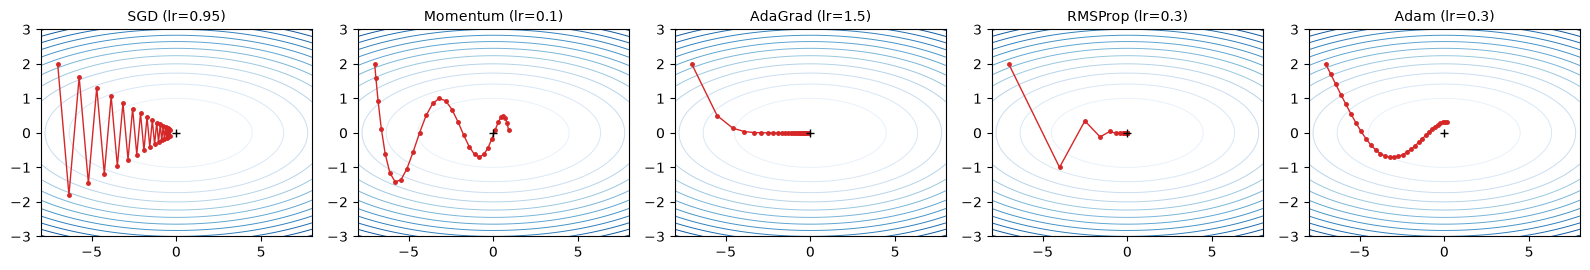

In [45]:
def run_optimizer(opt, steps: int = 30) -> np.ndarray:
    """(-7, 2)에서 출발해 최적화 경로를 돌려줍니다."""
    params = {"x": np.array(-7.0), "y": np.array(2.0)}
    path = []
    for _ in range(steps):
        path.append((float(params["x"]), float(params["y"])))
        grads = {"x": params["x"] / 10, "y": 2 * params["y"]}
        opt.update(params, grads)
    path.append((float(params["x"]), float(params["y"])))
    return np.array(path)


optimizers = {
    "SGD (lr=0.95)": SGD(lr=0.95),
    "Momentum (lr=0.1)": Momentum(lr=0.1),
    "AdaGrad (lr=1.5)": AdaGrad(lr=1.5),
    "RMSProp (lr=0.3)": RMSProp(lr=0.3),
    "Adam (lr=0.3)": Adam(lr=0.3),
}

gx, gy = np.meshgrid(np.linspace(-8, 8, 200), np.linspace(-3, 3, 200))
fig, axes = plt.subplots(1, 5, figsize=(16, 2.8))
for ax, (name, opt) in zip(axes, optimizers.items()):
    path = run_optimizer(opt)
    ax.contour(gx, gy, gx ** 2 / 20 + gy ** 2, levels=12, cmap="Blues", linewidths=0.7)
    ax.plot(path[:, 0], path[:, 1], "o-", color="tab:red", markersize=2.5, linewidth=1)
    ax.plot(0, 0, "k+")
    ax.set_title(name, fontsize=10)
    print(f"{name:20s} 최종 위치 ({path[-1, 0]:.3f}, {path[-1, 1]:.3f})")
plt.tight_layout()
plt.show()

## 3.5 `torch.optim`

PyTorch는 자주 쓰는 옵티마이저를 클래스로 제공합니다. 다양한 옵티마이저의 인자와 수식은 [공식 문서](https://docs.pytorch.org/docs/stable/optim.html)에서 확인할 수 있습니다.

In [46]:
weight = torch.tensor([1.0], requires_grad=True)
trainable = [weight]     # 실제로는 model.parameters()

available = {
    "SGD": optim.SGD(trainable, lr=0.01, momentum=0.9),
    "Adam": optim.Adam(trainable, lr=0.01),
    "AdamW": optim.AdamW(trainable, lr=0.01),
    "Adagrad": optim.Adagrad(trainable, lr=0.01),
    "Adadelta": optim.Adadelta(trainable, lr=0.01),
    "RMSprop": optim.RMSprop(trainable, lr=0.01),
    "LBFGS": optim.LBFGS(trainable, lr=0.01),
}
# 이 밖에도 더 있습니다
print(list(available))
print(available["AdamW"])

['SGD', 'Adam', 'AdamW', 'Adagrad', 'Adadelta', 'RMSprop', 'LBFGS']
AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    weight_decay: 0.01
)


### 옵티마이저 사용하기

학습 루프에서 옵티마이저의 메서드 두 개를 매번 부릅니다.

- `zero_grad()`: 앞 스텝의 기울기를 비웁니다. 부르지 않으면 1강에서 본 대로 `.grad`에 더해집니다.
- `step()`: 지금 `.grad`에 든 값으로 파라미터를 고칩니다.

손실 함수는 출력과 목표값을 비교합니다. 어떤 함수의 값을 0으로 만들고 싶다면 목표값이 0인 손실을 쓰면 됩니다.

### 실습 3

$g(w) = 4|w - 3|$의 값이 0이 되는 $w$를 찾아가 봅시다. 시작값은 $w = -5$입니다. `optim.SGD(lr=0.02)`와 `nn.L1Loss()`를 쓰고 12번 반복하며 $g$의 값을 출력합니다. 마지막 반복의 손실을 `final_loss`에 저장하세요.

In [47]:
def v_shape(w: torch.Tensor) -> torch.Tensor:
    return 4 * (w - 3).abs()

w = torch.tensor([-5.0], requires_grad=True)
goal = torch.tensor([0.0])

# 여기에 optimizer와 손실 함수를 정의하고, 반복문을 작성하세요

<details><summary>정답</summary>

```python
def v_shape(w: torch.Tensor) -> torch.Tensor:
    return 4 * (w - 3).abs()

w = torch.tensor([-5.0], requires_grad=True)
goal = torch.tensor([0.0])

optimizer = optim.SGD([w], lr=0.02)
criterion = nn.L1Loss()

for step in range(12):
    value = v_shape(w)
    loss = criterion(value, goal)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    print(f"step {step}: g = {value.item():.2f}")

final_loss = loss.item()
assert abs(final_loss - 28.48) < 1e-3      # 스텝마다 w가 0.08씩 움직여 g가 0.32씩 줄어든다
```
</details>

### 최적화 과정 보기

실제로 옵티마이저를 쓰면 어떻게 움직이는지 봅시다. 골짜기가 여러 개인 함수 $0.1(x-1)^2 + \cos 2x$에서 $x = -6$으로 출발합니다. 이 함수의 전체 최솟값은 $x \approx 1.5$이고, 출발점 옆에 $x \approx -4.4$의 작은 골짜기(local minimum)가 있습니다.

네 가지 설정을 비교합니다. 숫자는 움직인 순서이고 5스텝마다 적었습니다. 옵티마이저 사용과 경로 관찰이라는 실습 구성은 [webconf-pytorch-workshop](https://github.com/theevann/webconf-pytorch-workshop)을 참고했습니다.

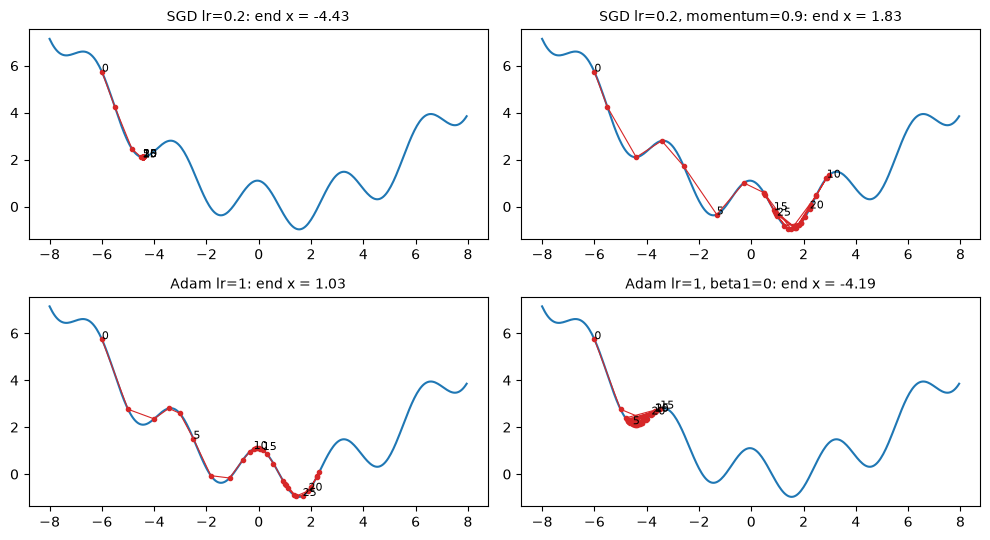

In [48]:
def wavy_bowl(x: torch.Tensor) -> torch.Tensor:
    return 0.1 * (x - 1) ** 2 + torch.cos(2 * x)


def follow_path(make_optimizer, start: float = -6.0, steps: int = 30) -> list:
    """최적화 경로를 (위치, 함숫값) 목록으로 돌려줍니다."""
    position = torch.tensor([start], requires_grad=True)
    optimizer = make_optimizer([position])
    visited = []
    for _ in range(steps):
        optimizer.zero_grad()
        height = wavy_bowl(position)
        height.backward()
        visited.append((position.item(), height.item()))
        optimizer.step()
    return visited


curve_x = torch.arange(-8, 8, 0.05)
settings = {
    "SGD lr=0.2": lambda p: optim.SGD(p, lr=0.2),
    "SGD lr=0.2, momentum=0.9": lambda p: optim.SGD(p, lr=0.2, momentum=0.9),
    "Adam lr=1": lambda p: optim.Adam(p, lr=1.0),
    "Adam lr=1, beta1=0": lambda p: optim.Adam(p, lr=1.0, betas=(0.0, 0.999)),
}
fig, axes = plt.subplots(2, 2, figsize=(10, 5.5))
for ax, (name, make_optimizer) in zip(axes.flat, settings.items()):
    visited = follow_path(make_optimizer)
    ax.plot(curve_x, wavy_bowl(curve_x))
    ax.plot(*zip(*visited), "o-", color="tab:red", markersize=3, linewidth=0.8)
    for i, (px, py) in enumerate(visited):
        if i % 5 == 0:
            ax.annotate(str(i), (px, py), fontsize=8)
    ax.set_title(f"{name}: end x = {visited[-1][0]:.2f}", fontsize=10)
plt.tight_layout()
plt.show()

- **SGD**는 출발점 옆의 작은 골짜기에 멈춥니다. 기울기가 0이 되면 더 움직일 이유가 없기 때문입니다.
- **momentum을 켠 SGD**와 **Adam**은 관성으로 언덕을 넘어 전체 최솟값 근처까지 갑니다.
- **관성을 뺀 Adam**(`beta1=0`)은 같은 학습률에서도 넘어가지 못합니다. 언덕을 넘긴 것이 관성이었다는 뜻입니다.

이것은 이 함수, 이 출발점, 이 학습률에서의 결과입니다. Adam이 항상 전체 최솟값을 찾는다는 뜻은 아닙니다. 예를 들어 `start=6.0`으로 바꾸면 lr=1인 Adam은 $x \approx 4.5$의 골짜기 근처에 머뭅니다. `follow_path`의 출발점과 학습률을 바꿔 직접 시험해 보세요.

## 3.6 Learning Rate 복습

- Learning rate가 크면 어떻게 되나요?
- Learning rate가 작으면 어떻게 되나요?
- 그럼 Learning rate는 큰 게 좋나요, 작은 게 좋나요?

([참고 그림](https://t1.daumcdn.net/cfile/tistory/99D8634C5D89919B21))

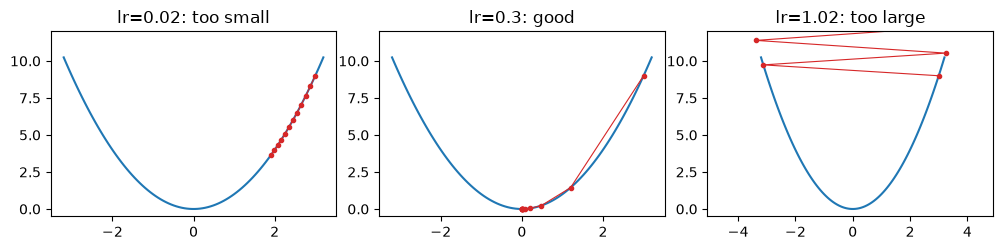

In [49]:
curve = np.linspace(-3.2, 3.2, 100)
fig, axes = plt.subplots(1, 3, figsize=(10, 2.6))
for ax, (lr, title) in zip(axes, [(0.02, "too small"), (0.3, "good"), (1.02, "too large")]):
    value, path = 3.0, []
    for _ in range(12):
        path.append(value)
        value = value - lr * 2 * value       # f(x) = x^2의 경사 하강
    path = np.array(path)
    ax.plot(curve, curve ** 2)
    ax.plot(path, path ** 2, "o-", color="tab:red", markersize=3, linewidth=0.8)
    ax.set_title(f"lr={lr}: {title}")
    ax.set_ylim(-0.5, 12)
plt.tight_layout()
plt.show()

### 왜 Learning Rate를 항상 고정해야 하지?

- Learning rate가 작으면 최소 손실에 가장 가깝게 갈 수 있습니다.
- Learning rate가 크면 빠르게 학습할 수 있습니다.
- 그렇다면 **처음엔 빠르게 학습하다가, 수렴할 때 learning rate를 줄이면** 되지 않을까요? ([참고 그림](https://velog.velcdn.com/images%2Freversesky%2Fpost%2F07c4a671-0bbd-4fb1-914f-9d4f0ad24797%2Fimage.png))

## 3.7 Scheduler

**스케줄러**는 학습률을 학습 도중에 바꾸는 방법입니다. 예시를 먼저 봅시다. 실습 3의 $g(w) = 4|w - 3|$를 lr=0.3으로 최적화합니다. 기울기의 크기가 항상 4이므로, 고정 학습률이면 정답 근처에서 계속 왔다 갔다 합니다.

step  0: g = 32.0000, 다음 lr = 0.2700
step  1: g = 27.2000, 다음 lr = 0.2430
step  2: g = 22.8800, 다음 lr = 0.2187
step  3: g = 18.9920, 다음 lr = 0.1968
step  4: g = 15.4928, 다음 lr = 0.1771
step  5: g = 12.3435, 다음 lr = 0.1594
step  6: g =  9.5092, 다음 lr = 0.1435
step  7: g =  6.9583, 다음 lr = 0.1291
step  8: g =  4.6624, 다음 lr = 0.1162
step  9: g =  2.5962, 다음 lr = 0.1046
step 10: g =  0.7366, 다음 lr = 0.0941
step 11: g =  0.9371, 다음 lr = 0.0847


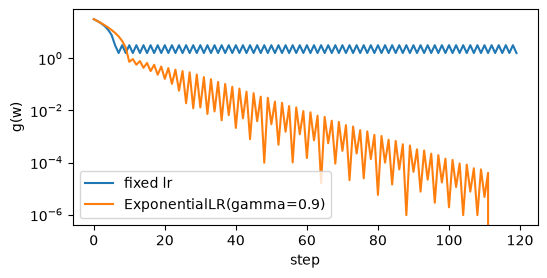

고정 학습률의 마지막 네 값: [3.2, 1.6, 3.2, 1.6]
스케줄러의 마지막 값: 0.0000


In [50]:
def descend_v_shape(gamma: float | None, steps: int = 120) -> list:
    """g(w)를 최적화하며 값의 변화를 돌려줍니다. gamma를 주면 학습률을 매 스텝 gamma배 합니다."""
    w = torch.tensor([-5.0], requires_grad=True)
    optimizer = optim.SGD([w], lr=0.3)
    scheduler = optim.lr_scheduler.ExponentialLR(optimizer, gamma) if gamma else None

    values = []
    for step in range(steps):
        value = v_shape(w)
        optimizer.zero_grad()
        value.backward()
        optimizer.step()
        if scheduler:
            scheduler.step()
        values.append(value.item())
        if scheduler and step < 12:
            print(f"step {step:2d}: g = {value.item():7.4f}, 다음 lr = {optimizer.param_groups[0]['lr']:.4f}")
    return values


with_scheduler = descend_v_shape(gamma=0.9)
fixed = descend_v_shape(gamma=None)
plt.figure(figsize=(6, 2.8))
plt.plot(fixed, label="fixed lr")
plt.plot(with_scheduler, label="ExponentialLR(gamma=0.9)")
plt.yscale("log")
plt.xlabel("step")
plt.ylabel("g(w)")
plt.legend()
plt.show()
print("고정 학습률의 마지막 네 값:", [round(v, 2) for v in fixed[-4:]])
print(f"스케줄러의 마지막 값: {with_scheduler[-1]:.4f}")

### 스케줄러의 종류

| 스케줄러 | 동작 | 예시 |
|---|---|---|
| `LambdaLR` | 초기 학습률에 함수의 결과를 곱함 | `lr_lambda=lambda epoch: 0.95 ** epoch`이면 $LR = LR_0 \times 0.95^{epoch}$ |
| `MultiplicativeLR` | **현재** 학습률에 함수의 결과를 곱함 | `lr_lambda=lambda epoch: 0.95`이면 매번 0.95배 |
| `StepLR` | `step_size`마다 `gamma`를 곱함 | `step_size=10, gamma=0.5`이면 $LR = LR_0 \times 0.5^{\lfloor epoch/10 \rfloor}$ |
| `MultiStepLR` | 지정한 epoch에 `gamma`를 곱함 | `milestones=[30, 80], gamma=0.5`이면 30, 80에서 반으로 |
| `ExponentialLR` | 매번 `gamma`를 곱함 | $LR = LR_0 \times \gamma^{epoch}$ |
| `CosineAnnealingLR` | 코사인 곡선을 따라 `T_max`까지 줄임. 긴 학습에서 흔히 씀 | `T_max=100`이면 100 epoch에 걸쳐 0까지 |
| `ReduceLROnPlateau` | 성능이 나아지지 않을 때 줄임. `step`에 손실을 넣어 줘야 함 | `ReduceLROnPlateau(optimizer, 'min')`이면 손실이 줄지 않을 때 감소 |

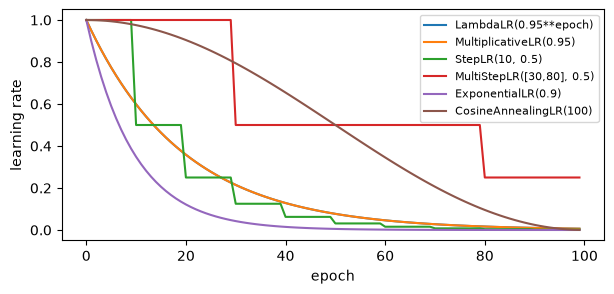

In [51]:
def lr_curve(make_scheduler, epochs: int = 100) -> list:
    """스케줄러에 따라 학습률이 어떻게 변하는지 돌려줍니다."""
    optimizer = optim.SGD([torch.zeros(1, requires_grad=True)], lr=1.0)
    scheduler = make_scheduler(optimizer)
    history = []
    for _ in range(epochs):
        history.append(optimizer.param_groups[0]["lr"])
        optimizer.step()
        scheduler.step()
    return history


schedulers = {
    "LambdaLR(0.95**epoch)": lambda o: optim.lr_scheduler.LambdaLR(o, lr_lambda=lambda epoch: 0.95 ** epoch),
    "MultiplicativeLR(0.95)": lambda o: optim.lr_scheduler.MultiplicativeLR(o, lr_lambda=lambda epoch: 0.95),
    "StepLR(10, 0.5)": lambda o: optim.lr_scheduler.StepLR(o, step_size=10, gamma=0.5),
    "MultiStepLR([30,80], 0.5)": lambda o: optim.lr_scheduler.MultiStepLR(o, milestones=[30, 80], gamma=0.5),
    "ExponentialLR(0.9)": lambda o: optim.lr_scheduler.ExponentialLR(o, gamma=0.9),
    "CosineAnnealingLR(100)": lambda o: optim.lr_scheduler.CosineAnnealingLR(o, T_max=100),
}
plt.figure(figsize=(7, 3))
for name, make_scheduler in schedulers.items():
    plt.plot(lr_curve(make_scheduler), label=name)
plt.xlabel("epoch")
plt.ylabel("learning rate")
plt.legend(fontsize=8)
plt.show()

### 스케줄러 효과 비교: MNIST

MNIST 분류 MLP로 비교합니다. 데이터와 학습 코드는 5부에서 자세히 다루니, 지금은 **학습률 변화와 테스트 손실의 관계**만 보세요.

- 고정 학습률
- `MultiplicativeLR`: 매 epoch 0.7배
- `ReduceLROnPlateau`: 테스트 손실이 나아지지 않을 때 감소

> **주의**: `MultiplicativeLR`은 **현재** 학습률에 곱합니다. `lr_lambda=lambda epoch: 0.7 ** epoch`처럼 쓰면 곱이 누적되어 학습률이 금방 0에 가까워집니다. 지수 형태는 `LambdaLR`에 쓰세요.
>
> 실무에서는 스케줄러를 고를 때 테스트 데이터가 아닌 **별도의 검증 데이터**를 씁니다. 여기서는 단순하게 보기 위해 테스트 데이터를 썼습니다.

In [52]:
BATCH_SIZE = 32
EPOCHS = 6

# 이미지를 CHW 텐서로 바꾸고 값의 범위를 [0, 1]로 맞춘다(1강 5.2절)
to_tensor = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
train_dataset = torchvision.datasets.MNIST(root="./data", train=True, download=True, transform=to_tensor)
test_dataset = torchvision.datasets.MNIST(root="./data", train=False, download=True, transform=to_tensor)
train_loader = torch.utils.data.DataLoader(dataset=train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = torch.utils.data.DataLoader(dataset=test_dataset, batch_size=BATCH_SIZE, shuffle=False)


class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(28 * 28, 512)
        self.fc2 = nn.Linear(512, 256)
        self.fc3 = nn.Linear(256, 10)
        self.dropout_prob = 0.5                  # 50%의 노드를 끄는 설정
        self.batch_norm1 = nn.BatchNorm1d(512)   # 1차원 입력이므로 BatchNorm1d
        self.batch_norm2 = nn.BatchNorm1d(256)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = x.view(-1, 28 * 28)
        x = self.fc1(x)
        x = self.batch_norm1(x)
        x = F.relu(x)
        x = F.dropout(x, training=self.training, p=self.dropout_prob)
        x = self.fc2(x)
        x = self.batch_norm2(x)
        x = F.relu(x)
        x = F.dropout(x, training=self.training, p=self.dropout_prob)
        return self.fc3(x)     # CrossEntropyLoss가 softmax를 포함하므로 그대로 반환


def train_with_scheduler(make_scheduler) -> tuple[list, list]:
    """스케줄러를 바꿔 가며 학습하고, epoch별 테스트 손실과 학습률을 돌려줍니다."""
    set_seed()
    model = MLP().to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    scheduler = make_scheduler(optimizer) if make_scheduler else None

    test_losses, learning_rates = [], []
    for epoch in range(EPOCHS):
        model.train()
        for image, label in train_loader:
            image, label = image.to(device), label.to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(image), label)
            loss.backward()
            optimizer.step()

        model.eval()
        test_loss = 0.0
        with torch.no_grad():
            for image, label in test_loader:
                image, label = image.to(device), label.to(device)
                test_loss += loss_fn(model(image), label).item()
        test_loss /= len(test_loader)

        test_losses.append(test_loss)
        learning_rates.append(optimizer.param_groups[0]["lr"])
        print(f"epoch {epoch}: lr {learning_rates[-1]:.6f}, test loss {test_loss:.4f}")

        if isinstance(scheduler, ReduceLROnPlateau):
            scheduler.step(test_loss)      # 이 스케줄러만 손실을 넣어 준다
        elif scheduler:
            scheduler.step()
    return test_losses, learning_rates


results = {}
for name, make_scheduler in {
    "fixed": None,
    "MultiplicativeLR(0.7)": lambda o: optim.lr_scheduler.MultiplicativeLR(o, lr_lambda=lambda epoch: 0.7),
    "ReduceLROnPlateau": lambda o: ReduceLROnPlateau(o, "min", factor=0.5, patience=0),
}.items():
    print(name)
    results[name] = train_with_scheduler(make_scheduler)

fixed


epoch 0: lr 0.001000, test loss 0.1200


epoch 1: lr 0.001000, test loss 0.0873


epoch 2: lr 0.001000, test loss 0.0735


epoch 3: lr 0.001000, test loss 0.0732


epoch 4: lr 0.001000, test loss 0.0688


... (9 outputs left out)

epoch 2: lr 0.001000, test loss 0.0735


epoch 3: lr 0.001000, test loss 0.0732


epoch 4: lr 0.001000, test loss 0.0688


epoch 5: lr 0.001000, test loss 0.0656


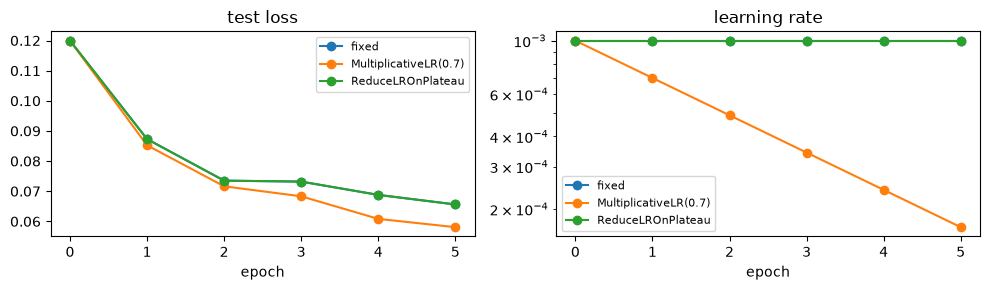

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for name, (test_losses, learning_rates) in results.items():
    axes[0].plot(test_losses, "o-", label=name)
    axes[1].plot(learning_rates, "o-", label=name)
axes[0].set_title("test loss")
axes[1].set_title("learning rate")
axes[1].set_yscale("log")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

`ReduceLROnPlateau`는 테스트 손실이 나아지지 않을 때만 학습률을 줄입니다. 위에서는 `patience=0`으로 한 번만 나아지지 않아도 반으로 줄이게 했습니다. 실제로는 잠깐의 흔들림에 반응하지 않도록 `patience`를 더 크게 둡니다.

그런데 저장된 출력에서는 6 epoch 내내 손실이 조금씩이라도 줄어(0.0735에서 0.0732로 줄어든 구간도 있습니다) 학습률이 **한 번도 줄지 않았습니다**. 그래서 `fixed`와 값이 같고 그래프의 선도 겹칩니다. 줄어드는 모습은 손실 값을 직접 넣어 확인합시다.

In [54]:
demo_optimizer = optim.SGD([torch.zeros(1, requires_grad=True)], lr=1.0)
demo_scheduler = ReduceLROnPlateau(demo_optimizer, "min", factor=0.5, patience=0)

for val_loss in [1.0, 0.8, 0.9, 0.7, 0.75, 0.6]:      # 0.9와 0.75에서 나빠진다
    demo_scheduler.step(val_loss)
    print(f"loss {val_loss:.2f} -> lr {demo_optimizer.param_groups[0]['lr']}")
assert demo_optimizer.param_groups[0]["lr"] == 0.25

loss 1.00 -> lr 1.0
loss 0.80 -> lr 1.0
loss 0.90 -> lr 0.5
loss 0.70 -> lr 0.5
loss 0.75 -> lr 0.25
loss 0.60 -> lr 0.25


> `threshold`(기본 상대값 `1e-4`)보다 작은 개선은 나아진 것으로 치지 않습니다. 0.0735에서 0.0732로의 개선은 이 값을 넘습니다.

> 시드 하나로 짧게 돌린 결과이므로, 작은 차이로 어느 스케줄러가 더 좋다고 결론 내리면 안 됩니다. 제대로 비교하려면 시드를 바꿔 여러 번 돌려야 합니다.

### 실습 4

다양한 스케줄러를 적용하며 결과를 확인해 봅시다. 위의 `train_with_scheduler`에 `StepLR(step_size=2, gamma=0.5)`을 넘겨 학습하고, 반환된 학습률 목록을 `step_lrs`에 저장하세요. 표의 다른 스케줄러도 시도해 보세요.

In [55]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
_, step_lrs = train_with_scheduler(lambda o: optim.lr_scheduler.StepLR(o, step_size=2, gamma=0.5))
assert abs(step_lrs[0] - 0.001) < 1e-9
assert abs(step_lrs[2] - 0.0005) < 1e-9
assert abs(step_lrs[4] - 0.00025) < 1e-9
print(step_lrs)
```
</details>

---
# 4부. Weight Initialize

가중치를 처음에 어떤 값으로 시작할까요? 지금은 대부분 직접 하지 않습니다. PyTorch의 `nn.Linear`, `nn.Conv2d`는 알아서 초기화합니다. 내부에서 `kaiming_uniform_`을 부르지만 인자(`a=√5`)가 달라, 실제로는 $\pm 1/\sqrt{n}$ 범위의 균등 분포이고 분산이 He의 약 1/6입니다. 그래도 **왜 이런 방법이 나왔는지** 알아 두면 학습이 안 될 때 원인을 찾을 수 있습니다.

참고: [가중치 초기화 설명](https://yngie-c.github.io/deep%20learning/2020/03/17/parameter_init/) · [비교 그림](https://user-images.githubusercontent.com/45377884/91631652-2fc76c00-ea16-11ea-98f2-3dc11c0f5f43.png)

## 4.1 Zero Initialize

**모든 가중치를 0으로 초기화**합니다.

- 네트워크의 모든 가중치가 동일하므로 연산의 다양성이 사라집니다.
- 입력이 들어와도 한 레이어 안의 여러 노드가 똑같은 출력값을 내놓습니다.
- 결국 여러 노드를 쓰는 의미가 없어지고, 노드 하나만 레이어에 넣은 것과 같습니다.

> 비추천입니다! 0이 아니어도 **모든 값이 같으면** 같은 문제가 생깁니다. 아래에서 확인합니다.

In [56]:
def train_toy(init_fn) -> nn.Sequential:
    """주어진 방법으로 초기화한 2층 신경망을 잠깐 학습해 돌려줍니다."""
    set_seed()
    net = nn.Sequential(nn.Linear(4, 3), nn.ReLU(), nn.Linear(3, 1))
    for layer in (net[0], net[2]):
        init_fn(layer.weight)
        nn.init.zeros_(layer.bias)
    optimizer = optim.SGD(net.parameters(), lr=0.01)
    inputs, targets = torch.randn(32, 4), torch.randn(32, 1)
    for _ in range(50):
        loss = F.mse_loss(net(inputs), targets)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return net


zero_net = train_toy(nn.init.zeros_)
print("0으로 초기화: 학습 후 첫 층 가중치의 절댓값 최대 =", zero_net[0].weight.abs().max().item())
assert zero_net[0].weight.abs().max() == 0       # 기울기가 0이라 전혀 학습되지 않는다

same_net = train_toy(lambda w: nn.init.constant_(w, 0.5))
print("\n모두 0.5로 초기화: 학습 후 첫 층 가중치")
print(same_net[0].weight.data)                   # 노드(행)들이 똑같이 움직인다
assert torch.equal(same_net[0].weight[0], same_net[0].weight[1])

normal_net = train_toy(nn.init.normal_)          # 정규 분포 초기화
print("\n정규 분포로 초기화: 학습 후 첫 층 가중치")
print(normal_net[0].weight.data)

0으로 초기화: 학습 후 첫 층 가중치의 절댓값 최대 = 0.0

모두 0.5로 초기화: 학습 후 첫 층 가중치
tensor([[0.4727, 0.5181, 0.4560, 0.4517],
        [0.4727, 0.5181, 0.4560, 0.4517],
        [0.4727, 0.5181, 0.4560, 0.4517]])

정규 분포로 초기화: 학습 후 첫 층 가중치
tensor([[-1.1720,  1.3291, -0.4282,  1.6820],
        [ 0.5616,  1.0098,  1.7833,  1.0301],
        [-0.8548, -1.1513, -0.4694,  0.0764]])


## 4.2 Random Initialize

**모든 가중치를 평균과 표준편차를 이용한 확률분포에 따라 초기화**합니다. 그런데 표준편차가 문제입니다. 층을 지나며 활성값이 어떻게 변하는지 직접 그려 봅시다. 맨 윗줄과 그 아래 줄을 보세요.

- 표준편차가 크면(`1`): sigmoid를 지나자 값이 0과 1 양극단으로 치우쳐, 기울기가 사라져 학습이 안 됩니다.
- 표준편차가 작으면(`0.01`): 값이 하나로 몰려, Zero Initialize와 같은 문제가 생깁니다.

그림: [표준편차 1](https://user-images.githubusercontent.com/45377884/91642462-852b6980-ea66-11ea-84cd-2cdbc3007db1.png) · [표준편차 0.01](https://user-images.githubusercontent.com/45377884/91642484-aab87300-ea66-11ea-94ba-f0236b3fe508.png)

sigmoid, std=1       층별 활성값 표준편차: [0.459, 0.441, 0.439, 0.418, 0.429]


sigmoid, std=0.01    층별 활성값 표준편차: [0.025, 0.013, 0.013, 0.012, 0.012]
sigmoid, Xavier      층별 활성값 표준편차: [0.207, 0.134, 0.13, 0.115, 0.114]
ReLU, Xavier         층별 활성값 표준편차: [0.583, 0.432, 0.307, 0.185, 0.119]
ReLU, He             층별 활성값 표준편차: [0.824, 0.864, 0.867, 0.739, 0.673]


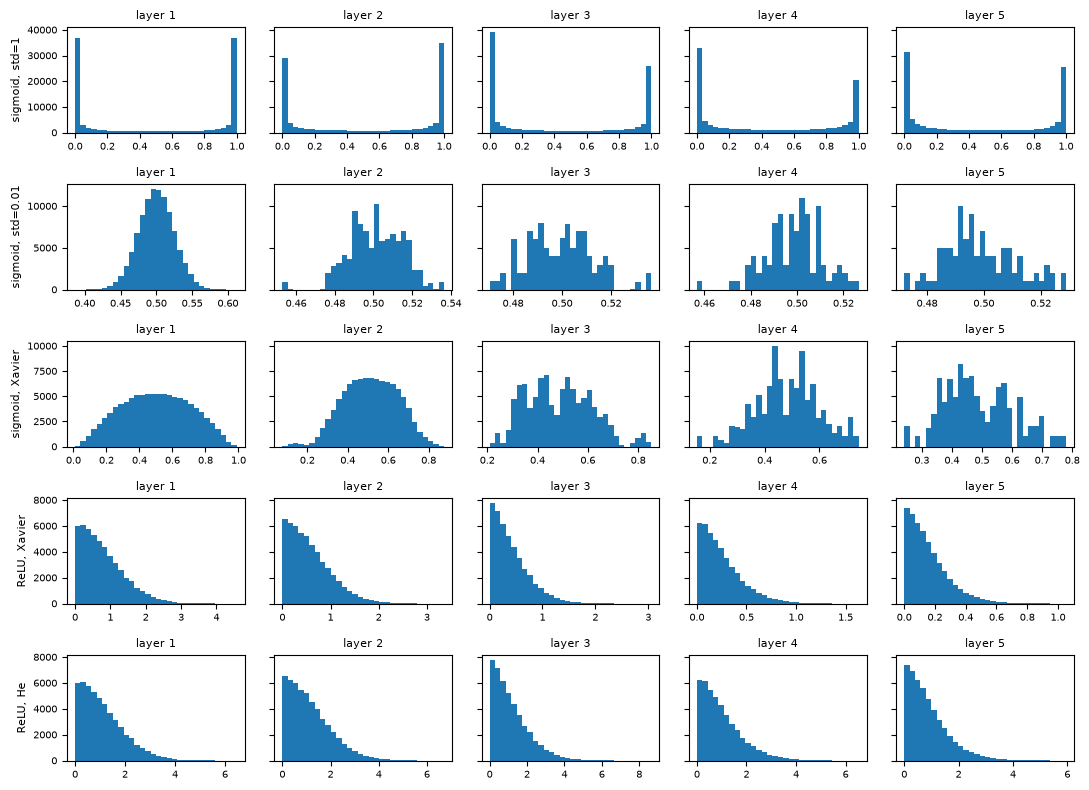

In [57]:
def layer_activations(activation, init_fn, layers: int = 5, width: int = 100) -> list:
    """층을 지날 때의 활성값을 기록합니다."""
    set_seed()
    x = torch.randn(1000, width)
    outputs = []
    with torch.no_grad():
        for _ in range(layers):
            w = torch.empty(width, width)
            init_fn(w)
            x = activation(x @ w)
            outputs.append(x.flatten())
    return outputs


experiments = {
    "sigmoid, std=1": (torch.sigmoid, lambda w: nn.init.normal_(w, std=1.0)),
    "sigmoid, std=0.01": (torch.sigmoid, lambda w: nn.init.normal_(w, std=0.01)),
    "sigmoid, Xavier": (torch.sigmoid, nn.init.xavier_normal_),
    "ReLU, Xavier": (torch.relu, nn.init.xavier_normal_),
    "ReLU, He": (torch.relu, lambda w: nn.init.kaiming_normal_(w, nonlinearity="relu")),
}

fig, axes = plt.subplots(len(experiments), 5, figsize=(11, 8), sharey="row")
for row, (name, (activation, init_fn)) in zip(axes, experiments.items()):
    outs = layer_activations(activation, init_fn)
    for i, (ax, values) in enumerate(zip(row, outs)):
        # ReLU는 0에 몰린 값이 많으므로 0을 뺀 값의 분포를 그린다
        ax.hist(values[values > 0].numpy(), bins=30)
        ax.set_title(f"layer {i + 1}", fontsize=8)
        ax.tick_params(labelsize=7)
    row[0].set_ylabel(name, fontsize=8)
    print(f"{name:20s} 층별 활성값 표준편차:", [round(v.std().item(), 3) for v in outs])
plt.tight_layout()
plt.show()

## 4.3 Xavier Initialize

입력과 출력의 **분산을 같게** 유지하자는 방법입니다. 사람 이름입니다(Xavier Glorot).

$Y = \sum_i^n X_iW_i$에서 $X$와 $W$가 독립이고 평균이 0이라고 가정하면 분산을 분리할 수 있습니다. sigmoid 출력은 평균이 0이 아니므로 이 가정에서 벗어납니다.

$$\text{Var}(X_iW_i) = \text{Var}(X_i)\text{Var}(W_i), \qquad \text{Var}(Y) = n\text{Var}(X)\text{Var}(W)$$

$\text{Var}(Y) = \text{Var}(X)$가 목표이므로 $W$의 분산은 다음과 같습니다.

$$\text{Var}(W) = \frac{1}{n}$$

**이전 계층의 노드 수에 반비례하게 현재 계층 가중치의 분산을 설정**합니다. 위 그림의 세 번째 줄을 보세요. 층이 깊어질수록 분포가 조금씩 좁아지지만, 양극단으로 치우친 첫 줄이나 한 점에 몰린 둘째 줄보다 훨씬 고르게 퍼져 있습니다. ([그림](https://user-images.githubusercontent.com/45377884/91678679-24dd1a80-eb81-11ea-9637-abcdbcd3788c.png))

실제 구현은 역전파까지 고려해 입력과 출력 노드 수의 평균을 씁니다: $\text{Var}(W) = \frac{2}{n_{in} + n_{out}}$

In [58]:
layer = nn.Conv2d(1, 1, 2)
nn.init.xavier_uniform_(layer.weight)      # 균등 분포 버전
print(layer.weight.data)

tensor([[[[-0.2585,  0.6313],
          [ 0.5537, -0.3729]]]])


같은 초기화를 프레임워크마다 다음과 같이 부릅니다.

| 프레임워크 | Xavier | He |
|---|---|---|
| PyTorch | `torch.nn.init.xavier_normal_()` | `torch.nn.init.kaiming_normal_()` |
| TensorFlow | `tf.keras.initializers.GlorotNormal()` | `tf.keras.initializers.HeNormal()` |

## 4.4 He Initialize

Xavier에서 **분산을 2배로 늘린 것**입니다.

$$\text{Var}(W) = \frac{2}{n}$$

ReLU는 0 이하의 값을 모두 0으로 바꾸므로, 층을 지날 때마다 절반가량이 사라져 분산이 줄어듭니다. 그래서 분산을 2배로 늘립니다.

위 그림의 네 번째 줄(ReLU + Xavier)과 다섯 번째 줄(ReLU + He)을 비교해 보세요. 출력된 층별 표준편차를 보면, Xavier는 층을 지날수록 빠르게 줄어들고 He는 훨씬 덜 줄어듭니다. (그림은 0에 몰린 값을 빼고 그렸습니다)

그림: [Xavier와 ReLU](https://user-images.githubusercontent.com/45377884/91679856-5efbeb80-eb84-11ea-870b-9fe512141ca5.png) · [He와 ReLU](https://user-images.githubusercontent.com/45377884/91680106-34f6f900-eb85-11ea-8abe-7bd830483f21.png)

In [59]:
layer = nn.Conv2d(1, 1, 2)
nn.init.kaiming_uniform_(layer.weight)     # Kaiming은 He의 이름입니다
print(layer.weight.data)

tensor([[[[ 0.8975,  0.7187],
          [ 0.9818, -1.0964]]]])


## 4.5 네트워크에서 initializer 바꾸기

층을 만든 뒤 `nn.init` 함수를 적용하면 됩니다. 층이 많으면 `model.apply`로 모든 층에 한 번에 적용합니다.

In [60]:
class InitNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(28 * 28, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 10)

        nn.init.kaiming_uniform_(self.fc1.weight)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = x.view(-1, 28 * 28)       # 입력을 편다: 784
        x = torch.relu(self.fc1(x))   # 784 -> 128
        x = torch.relu(self.fc2(x))   # 128 -> 64
        return self.fc3(x)            # 64 -> 10


net = InitNet()
print(net.fc1.weight.std().item())

0.0505194254219532


### 실습 5

`InitNet`의 모든 `nn.Linear` 층의 가중치를 Xavier 정규 분포(`nn.init.xavier_normal_`)로, 편향을 0으로 초기화하는 함수 `init_weights`를 작성하세요. `net.apply(init_weights)`로 적용합니다.

In [61]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def init_weights(m: nn.Module) -> None:
    if isinstance(m, nn.Linear):
        nn.init.xavier_normal_(m.weight)
        nn.init.zeros_(m.bias)

net = InitNet()
net.apply(init_weights)
assert net.fc2.bias.abs().sum() == 0
print(net.fc2.weight.std().item())
```
</details>

---
# 5부. Multi Layer Perceptron으로 MNIST 분류

이 강에서 배운 것을 모아 처음부터 끝까지 학습합니다.

## 5.1 Device 선언

CPU를 쓸지 GPU를 쓸지 정합니다.

In [62]:
# GPU를 사용할 수 있으면 사용하고, 그렇지 않으면 CPU를 사용합니다
if torch.cuda.is_available():
    device_name = "cuda:0"
else:
    device_name = "cpu"
device = torch.device(device_name)

print(device)

cpu


## 5.2 데이터 전처리 및 로드

용어를 먼저 정리합니다.

- **batch**: DataLoader가 한 번에 들고 오는 데이터 개수
- **shuffle**: 데이터 순서를 섞는 것
- **epoch**: 모든 데이터를 한 번 다 보는 것

전체 1000장일 때 배치 크기에 따라 다음과 같습니다.

| 배치 크기 | 1 epoch의 업데이트 횟수 | 이름 | 특징 |
|---|---|---|---|
| 10 | 100번 | 미니배치 | 업데이트가 잦지만 기울기가 많이 흔들림 |
| 100 | 10번 | 미니배치 | 가장 흔한 선택 |
| 1000 | 1번 | 풀배치 | 기울기는 안정적이지만 메모리가 많이 들고 업데이트가 드묾 |

In [63]:
transform = v2.Compose([v2.ToImage(),
                        v2.ToDtype(torch.float32, scale=True),
                        v2.Normalize((0.5,), (0.5,))])

batch_size = 64

train_dataset = torchvision.datasets.MNIST(root="./data", train=True, transform=transform, download=True)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

test_dataset = torchvision.datasets.MNIST(root="./data", train=False, transform=transform, download=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"학습 {len(train_dataset)}장, 테스트 {len(test_dataset)}장")

학습 60000장, 테스트 10000장


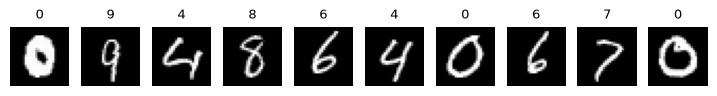

배치 모양: torch.Size([64, 1, 28, 28]) torch.Size([64])


In [64]:
# MNIST가 어떻게 생겼는지 봅시다. 참고 그림: https://upload.wikimedia.org/wikipedia/commons/2/27/MnistExamples.png
images, labels = next(iter(train_loader))
fig, axes = plt.subplots(1, 10, figsize=(9, 1.2))
for ax, image, label in zip(axes, images, labels):
    ax.imshow(image.squeeze(0), cmap="gray")
    ax.set_title(label.item(), fontsize=9)
    ax.axis("off")
plt.show()
print("배치 모양:", images.shape, labels.shape)

**Q. 환자 100명의 데이터가 총 10000장 있습니다. 사람마다 데이터 개수가 다릅니다. 환자 A의 데이터가 9900장이고, 나머지 99명이 합쳐서 100장입니다. 어떻게 나눠야 할까요?**

1. 이미지 단위로 섞어서 나누기: 학습 8000장, 테스트 2000장(테스트가 거의 A의 데이터)
2. 사람 단위로 나누기: 학습 80명, 테스트 20명
3. 사람 단위로 나누기: 학습 95명, 테스트 5명

<details><summary>답</summary>

**1번은 안 됩니다.** 같은 환자의 사진이 학습과 테스트에 함께 들어가 성능이 부풀려집니다. 반드시 **사람 단위**로 나눠야 합니다. 2번과 3번은 정답이 하나로 정해져 있지 않습니다. A가 어느 쪽에 들어가는지에 따라 결과가 크게 달라지므로, 교차 검증과 함께 A를 뺀 평가도 확인하는 것이 좋습니다.

> 물리적으로 격리된 신규 데이터에서도 충분한 성능을 내는 모델을 개발하는 것이 중요합니다.
</details>

## 5.3 네트워크 정의

입력 `784` → `128` → `64` → 출력 `10`인 다층 퍼셉트론입니다. 그림은 층마다 노드를 일부만 그렸고, 모든 노드가 다음 층의 모든 노드와 연결됩니다(완전연결).

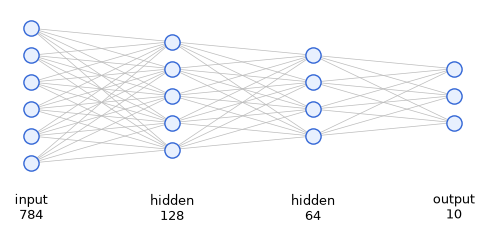

In [65]:
sizes = {"input\n784": 6, "hidden\n128": 5, "hidden\n64": 4, "output\n10": 3}
plt.figure(figsize=(6, 2.8))
positions = [[(i, j - (n - 1) / 2) for j in range(n)] for i, n in enumerate(sizes.values())]
for left, right in zip(positions, positions[1:]):
    for x0, y0 in left:
        for x1, y1 in right:
            plt.plot([x0, x1], [y0, y1], color="#bbbbbb", linewidth=0.5, zorder=1)
for i, (name, nodes) in enumerate(zip(sizes, positions)):
    plt.scatter(*zip(*nodes), s=120, color="#e8f0fe", edgecolors="#3367d6", zorder=2)
    plt.text(i, -3.6, name, ha="center", va="top", fontsize=9)
plt.ylim(-4.8, 3.2)
plt.axis("off")
plt.show()

In [66]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(28 * 28, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 10)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = x.view(-1, 28 * 28)        # 입력을 편다
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)
        return x

### 네트워크를 선언한 Device로 옮기기

In [67]:
set_seed()
net = Net()
net.to(device)

Net(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=10, bias=True)
)

### Loss 및 Optimizer 선언

In [68]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

## 5.4 Train Loop

In [69]:
num_epochs = 10
train_history = []

for epoch in range(num_epochs):
    net.train()
    running_loss = 0.0
    for inputs, labels in train_loader:
        inputs = inputs.to(device)      # 배치 x 1 x 28 x 28 (TensorFlow는 채널이 맨 뒤)
        labels = labels.to(device)      # 배치

        # 이전 스텝의 grad를 지운다. momentum 값은 옵티마이저가 따로 저장하므로 지워지지 않는다
        optimizer.zero_grad()
        outputs = net(inputs)           # 배치 x 10
        loss = loss_fn(outputs, labels)
        loss.backward()                 # 기울기 계산
        optimizer.step()                # 계산된 기울기로 가중치 업데이트
        running_loss += loss.item()

    train_history.append(running_loss / len(train_loader))
    print(f"Epoch {epoch + 1}, Loss: {train_history[-1]:.4f}")

print("Finished Training")

Epoch 1, Loss: 1.1235


Epoch 2, Loss: 0.3938


Epoch 3, Loss: 0.3292


Epoch 4, Loss: 0.2973


Epoch 5, Loss: 0.2724


Epoch 6, Loss: 0.2503


Epoch 7, Loss: 0.2308


Epoch 8, Loss: 0.2116


Epoch 9, Loss: 0.1943


Epoch 10, Loss: 0.1795
Finished Training


## 5.5 Test Loop

In [70]:
correct = 0
total = 0

net.eval()      # 학습할 때는 net.train()
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)
        outputs = net(inputs)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f"Accuracy on the test images: {accuracy}%")
assert accuracy > 80

Accuracy on the test images: 94.75%


### 실습 6

옵티마이저를 `Adam(lr=0.001)`으로 바꾸어 새 모델 `adam_net`을 3 epoch 학습하고, 테스트 정확도를 `adam_acc`(%)에 저장하세요. 위 SGD 결과의 앞쪽 epoch과 손실을 비교해 보세요.

In [71]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
set_seed()
adam_net = Net().to(device)
adam_opt = torch.optim.Adam(adam_net.parameters(), lr=0.001)
for epoch in range(3):
    adam_net.train()
    running_loss = 0.0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        adam_opt.zero_grad()
        loss = loss_fn(adam_net(inputs), labels)
        loss.backward()
        adam_opt.step()
        running_loss += loss.item()
    print(f"Epoch {epoch + 1}, Loss: {running_loss / len(train_loader):.4f}")

adam_net.eval()
correct = 0
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        correct += (adam_net(inputs).argmax(dim=1) == labels).sum().item()
adam_acc = 100 * correct / len(test_dataset)
assert adam_acc > 90
print(adam_acc)
```
</details>

## 5.6 코드 리뷰

아래 코드를 읽고 설명해 보세요. 1강 4부에서 본 `DynamicNet`을 학습한 뒤, 근사 결과를 $\sin(x)$와 함께 그립니다.

- `random.randint(4, 6)`은 4, 5, 6 중 하나입니다. `range`의 끝은 포함되지 않으므로, 더해지는 항은 없음, 4차, 4차와 5차 중 하나입니다.
- 왜 `momentum`을 쓸까요? 왜 학습률이 이렇게 작을까요?
- `detach()`는 왜 필요할까요?

<details><summary>답</summary>

- **학습률**: 손실이 2000개 점의 합(`reduction="sum"`)이고 $x^5$는 $x = \pi$에서 300이 넘어 기울기가 큽니다. 학습률이 크면 값이 발산합니다.
- **momentum**: 학습률이 아주 작아 혼자서는 거의 움직이지 못합니다. 이전 방향을 쌓아 움직임을 보탭니다.
- **`detach()`**: `requires_grad=True`로 만들어진 결과는 계산 그래프에 연결되어 있어 바로 `.numpy()`로 바꿀 수 없습니다. 그래프에서 떼어 낸 뒤 바꿉니다.
</details>

Epoch = 1999, loss = 803.0394287109375


Epoch = 3999, loss = 385.782470703125


Epoch = 5999, loss = 199.56808471679688


Epoch = 7999, loss = 95.53424072265625


Epoch = 9999, loss = 51.31558609008789
Result: y = -0.1562228947877884 + 0.7177331447601318 x + 0.028678424656391144 x^2 + -0.0727461501955986 x^3 + -0.0003315117210149765 x^4 ? + -0.0003315117210149765 x^5 ?


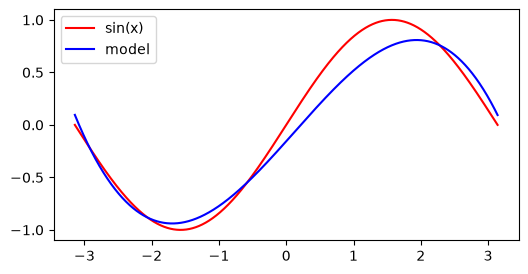

In [72]:
class DynamicNet(torch.nn.Module):
    def __init__(self):
        """다섯 개의 파라미터를 만들어 멤버로 등록합니다."""
        super().__init__()
        self.a = torch.nn.Parameter(torch.randn(()))
        self.b = torch.nn.Parameter(torch.randn(()))
        self.c = torch.nn.Parameter(torch.randn(()))
        self.d = torch.nn.Parameter(torch.randn(()))
        self.e = torch.nn.Parameter(torch.randn(()))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        y = self.a + self.b * x + self.c * x ** 2 + self.d * x ** 3
        for exp in range(4, random.randint(4, 6)):   # 항 없음, 4차, 또는 4차와 5차
            y = y + self.e * x ** exp
        return y

    def string(self) -> str:
        return f"y = {self.a.item()} + {self.b.item()} x + {self.c.item()} x^2 + {self.d.item()} x^3 + {self.e.item()} x^4 ? + {self.e.item()} x^5 ?"


set_seed()
x = torch.linspace(-math.pi, math.pi, 2000)
y = torch.sin(x)

model = DynamicNet()

criterion = torch.nn.MSELoss(reduction="sum")
optimizer = torch.optim.SGD(model.parameters(), lr=1e-8, momentum=0.9)
for t in range(10000):
    y_pred = model(x)

    loss = criterion(y_pred, y)
    if t % 2000 == 1999:
        print(f"Epoch = {t}, loss = {loss.item()}")

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print(f"Result: {model.string()}")

y_pred = model(x).detach().numpy()

plt.figure(figsize=(6, 3))
plt.plot(x.numpy(), y.numpy(), "r", label="sin(x)")
plt.plot(x.numpy(), y_pred, "b", label="model")
plt.legend()
plt.show()

## 5.7 (선택) 혼합 정밀도

GPU 학습에서는 **혼합 정밀도(automatic mixed precision, AMP)** 를 흔히 켭니다. 가능한 연산은 16비트 실수로 계산해 시간과 메모리를 아끼고, 정밀도가 필요한 연산은 32비트로 둡니다. ([공식 문서](https://docs.pytorch.org/docs/stable/amp.html))

- `torch.amp.autocast`: 구간 안의 연산을 알맞은 자료형으로 자동 실행합니다. 기본값은 GPU에서 `float16`, CPU에서 `bfloat16`입니다.
- `torch.amp.GradScaler`: `float16`에서는 작은 기울기가 0이 되어 사라질 수 있습니다. 손실을 키워서 미분하고, 갱신할 때 되돌려 이를 막습니다.

다른 코드에서 `torch.cuda.amp`를 보면 같은 기능입니다. 폐기 예정이니 새 코드에는 `torch.amp`를 쓰세요. 먼저 자료형이 어떻게 바뀌는지 봅시다. 가중치는 32비트 그대로이고, 구간 안의 계산 결과만 달라집니다.

In [73]:
layer = nn.Linear(4, 2)
sample = torch.rand(1, 4)
print("기본        :", layer(sample).dtype)

with torch.amp.autocast(device_type="cpu"):
    output = layer(sample)
print("autocast 안 :", output.dtype)
print("가중치      :", layer.weight.dtype)

기본        : torch.float32
autocast 안 : torch.bfloat16
가중치      : torch.float32


학습 루프에서는 순전파와 손실 계산만 `autocast`로 감싸고, `backward`와 `step`은 `scaler`를 거칩니다. `use_amp`가 `False`이면 두 도구 모두 아무 일도 하지 않아 일반 학습과 같습니다.

> 아래 저장된 출력은 **GPU가 없는 환경에서 AMP가 꺼진 채** 실행한 결과입니다. 그래서 속도나 정확도의 이득을 보여 주지 않습니다. T4 GPU로 바꿔 실행한 뒤, `use_amp`를 `False`로 고쳐 다시 돌려 출력되는 시간을 비교해 보세요.

In [74]:
use_amp = device.type == "cuda"     # GPU가 아니면 끈다

set_seed()
amp_net = Net().to(device)
amp_optimizer = torch.optim.Adam(amp_net.parameters(), lr=0.001)
scaler = torch.amp.GradScaler(device.type, enabled=use_amp)

start = time.perf_counter()
amp_net.train()
for inputs, labels in train_loader:
    inputs, labels = inputs.to(device), labels.to(device)
    amp_optimizer.zero_grad()
    with torch.amp.autocast(device_type=device.type, enabled=use_amp):
        loss = loss_fn(amp_net(inputs), labels)
    scaler.scale(loss).backward()     # 키운 손실로 미분
    scaler.step(amp_optimizer)        # 기울기를 되돌린 뒤 갱신
    scaler.update()                   # 다음 스텝의 배율 조정

print(f"AMP 사용: {use_amp}, 1 epoch {time.perf_counter() - start:.1f}초, 마지막 배치 손실: {loss.item():.4f}")

AMP 사용: False, 1 epoch 3.0초, 마지막 배치 손실: 0.0981


---
## 이 강의 요약

- `nn`은 클래스(상태를 저장), `F`는 함수입니다. 학습되는 값이 있으면 `nn`을 씁니다.
- `nn.CrossEntropyLoss`에는 **logit**을 넣습니다. `softmax`를 먼저 씌우지 않습니다. `log_softmax`를 돌려주는 모델에는 `NLLLoss`를 짝지웁니다.
- Adam은 RMSProp과 Momentum을 합친 방법이고, 첫 시도로 무난합니다. 가중치 감쇠를 함께 쓴다면 `AdamW`를 고릅니다.
- 스케줄러는 학습 중에 학습률을 줄입니다. `ReduceLROnPlateau`만 `step`에 값을 넣어 줍니다.
- 초기화는 sigmoid/tanh에 Xavier, ReLU에 He가 어울립니다. PyTorch의 기본 초기화로도 대부분 충분합니다.
- 데이터를 나눌 때는 **같은 대상(환자 등)이 학습과 테스트에 함께 들어가지 않게** 합니다.

## 숙제

1. **치트시트 추가**: `nn`과 `F`의 대표 기능을 각각 10개씩 정리해 1강의 치트시트에 더하세요.
2. **실험 보고**: MNIST MLP에서 은닉층 크기, 배치 크기, 옵티마이저, 학습률 중 하나를 바꾼 결과를 표로 정리해 보세요. 무엇이 정확도를 가장 크게 바꿨나요?

## 더 읽을거리

- [torch.optim 공식 문서](https://docs.pytorch.org/docs/stable/optim.html)
- [torch.nn.init 공식 문서](https://docs.pytorch.org/docs/stable/nn.init.html)
- [Decoupled Weight Decay Regularization](https://arxiv.org/abs/1711.05101): AdamW 논문